# Financial Markets Analytics Project

## Momentum Crashes and Volatility Targeting
### Does risk scaling protect momentum without the dangers of leverage?
### Evidence from the S&P 500 and STOXX Europe 600

### Research question

This project investigates whether volatility targeting can improve the risk
profile of a cross-sectional momentum strategy, with particular attention to
momentum crashes.

We compare three strategies:

1. Plain 12–1 cross-sectional momentum.
2. Standard volatility-targeted momentum, allowing leverage up to 2x.
3. No-leverage volatility-targeted momentum, where exposure cannot exceed 1x.

The analysis is performed independently on historical S&P 500 and STOXX Europe
600 constituents.

The main objective is not simply to maximize returns, but to understand:

- whether volatility targeting reduces drawdowns and extreme losses;
- when leverage improves or worsens momentum performance;
- whether the results are robust across US and European equities.

---

# 1. Data Loading and Investable Universe

## Objective of this section

In this section we load the historical S&P 500 and STOXX Europe 600 datasets
and identify which securities were actually part of each index at each point in time.

This step is essential because the datasets contain historical securities that may have
entered or exited the index during the sample period.

Using all securities simply because a price is available would introduce survivorship
and look-ahead problems into the backtest.

## Why historical membership matters

A security can have a recorded price even when it is no longer part of the index.

For this reason, the availability of a price is not enough to define the investable universe.

We use the historical index weights contained in the `Peso` sheet.

A security is considered active at time t if its historical index weight is positive:

$$
w_{i,t} > 0
$$

This allows us to reconstruct the actual index composition through time.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)

# The notebook expects the two Excel datasets in the same folder as the notebook.
DATA_DIR = Path(".")

SPX_FILE = DATA_DIR / "SPX500 Original.xlsm"
STOXX_FILE = DATA_DIR / "Stoxx 600 Originale.xlsm"


### What this code does

- `pandas` is used to work with tables and time series.
- `numpy` is used for numerical calculations.
- `matplotlib` is used to create graphs.
- `warnings` is used only to suppress non-critical warning messages.
- `pathlib.Path` makes the file references portable across computers.

The notebook expects `SPX500 Original.xlsm` and `Stoxx 600 Originale.xlsm` to be
stored in the same folder as the notebook. This avoids machine-specific absolute
file paths and makes the analysis easier to reproduce.


In [ ]:
def load_market_data(file_path):

    prices_raw = pd.read_excel(
        file_path,
        sheet_name="Price",
        header=[0, 1],
        index_col=0
    )

    weights_raw = pd.read_excel(
        file_path,
        sheet_name="Peso",
        header=[0, 1],
        index_col=0
    )

    # Convert dates into proper datetime format
    prices_raw.index = pd.to_datetime(prices_raw.index)
    weights_raw.index = pd.to_datetime(weights_raw.index)

    # Keep ticker as column identifier
    prices_raw.columns = prices_raw.columns.get_level_values(0)
    weights_raw.columns = weights_raw.columns.get_level_values(0)

    # Convert non-numeric values to NaN
    prices = prices_raw.apply(pd.to_numeric, errors="coerce")
    weights = weights_raw.apply(pd.to_numeric, errors="coerce")

    # Keep only dates and securities appearing in both datasets
    common_dates = prices.index.intersection(weights.index)
    common_tickers = prices.columns.intersection(weights.columns)

    prices = prices.loc[common_dates, common_tickers].sort_index()
    weights = weights.loc[common_dates, common_tickers].sort_index()

    return prices, weights

### Explanation

The function reads two sheets from each Excel workbook:

- `Price`: historical monthly security prices.
- `Peso`: historical index weights.

The datasets use a two-level header:
one level contains the ticker and another level contains the company name.

For the calculations we use the ticker as the main identifier.

We then convert:

- dates into proper date format;
- non-numeric cells into missing values (`NaN`);
- the two datasets to the same set of dates and securities.

This ensures that prices and weights are perfectly aligned before starting the analysis.

In [ ]:
spx_prices, spx_weights = load_market_data(SPX_FILE)
stoxx_prices, stoxx_weights = load_market_data(STOXX_FILE)

print("S&P 500")
print("Prices:", spx_prices.shape)
print("Sample:", spx_prices.index.min(), "to", spx_prices.index.max())

print("\nSTOXX 600")
print("Prices:", stoxx_prices.shape)
print("Sample:", stoxx_prices.index.min(), "to", stoxx_prices.index.max())

S&P 500
Prices: (336, 1355)
Sample: 1990-12-31 00:00:00 to 2018-11-30 00:00:00

STOXX 600
Prices: (192, 1255)
Sample: 2002-12-31 00:00:00 to 2018-11-30 00:00:00


### Interpretation

The number of columns is larger than 500 for the S&P 500 and larger than 600
for the STOXX 600.

This is expected.

The files contain all securities that entered or exited the indices during the historical sample,
not only the securities that were members at the end of the period.

This is useful because it allows us to reduce survivorship bias.

In [ ]:
spx_active = spx_weights.notna() & (spx_weights > 0)

stoxx_active = stoxx_weights.notna() & (stoxx_weights > 0)

## Historical membership

The variables `spx_active` and `stoxx_active` are Boolean matrices.

For every security and every month:

- `True` means that the security was a member of the index.
- `False` means that it was not.

This will be used to determine which securities were actually investable at each point in time.

In [ ]:
membership_summary = pd.DataFrame({
    "SPX500": spx_active.sum(axis=1),
    "STOXX600": stoxx_active.sum(axis=1)
})

print("S&P 500:")
print(spx_active.sum(axis=1).describe())

print("\nSTOXX 600:")
print(stoxx_active.sum(axis=1).describe())

S&P 500:
count    336.000000
mean     500.616071
std        1.645866
min      498.000000
25%      500.000000
50%      500.000000
75%      500.000000
max      506.000000
dtype: float64

STOXX 600:
count    192.000000
mean     600.000000
std        0.204658
min      599.000000
25%      600.000000
50%      600.000000
75%      600.000000
max      601.000000
dtype: float64


In [ ]:
spx_returns_raw = spx_prices.pct_change(fill_method=None)
stoxx_returns_raw = stoxx_prices.pct_change(fill_method=None)

## From prices to returns

Investment strategies are evaluated using returns rather than price levels.

The simple monthly return is:

$$
R_{i,t} = \frac{P_{i,t}}{P_{i,t-1}} - 1
$$

Example:

If a stock moves from 100 to 105:

$$
R = \frac{105}{100} - 1 = 5\%
$$

The function `pct_change()` computes exactly this quantity for every security.

In [ ]:
spx_active_lagged = spx_active.shift(1, fill_value=False)
stoxx_active_lagged = stoxx_active.shift(1, fill_value=False)

In [ ]:
spx_returns = spx_returns_raw.where(spx_active_lagged)

stoxx_returns = stoxx_returns_raw.where(stoxx_active_lagged)

## Avoiding look-ahead bias

This is one of the most important methodological choices in the project.

When we calculate the portfolio return in month \(t\), we only use membership information
that was known at the end of month \(t-1\).

Therefore we lag the membership matrix by one month.

This avoids using future information.

For example, if a stock is removed from the index during February, a portfolio created
at the end of January could still have held that stock during February.

Removing the February return only because the stock is no longer a constituent at the end
of the month would artificially remove losses from the backtest.

This would create look-ahead and survivorship bias.

---


# 2. Plain 12–1 Cross-Sectional Momentum

## Objective

In this section we construct the baseline cross-sectional momentum strategy.

The basic idea of momentum is simple:

> securities that performed relatively well in the recent past are classified as
> "winners", while securities that performed relatively poorly are classified as
> "losers".

Each month, securities are ranked according to their past performance.

The strategy then:

- goes long the top 10% of securities;
- goes short the bottom 10%;
- assigns equal weights within each group.

This plain momentum strategy will serve as the benchmark against which the
volatility-targeted strategies will later be compared.

## Long and short positions

A long position benefits when the price of a security increases.

A short position benefits when the price of a security decreases.

The return of the momentum long-short portfolio can therefore be written as:

$$
R^{MOM}_t =
R^{Winners}_t - R^{Losers}_t
$$

where:

- \(R^{Winners}_t\) is the average return of the winner portfolio;
- \(R^{Losers}_t\) is the average return of the loser portfolio.

The strategy is therefore based on relative performance rather than on the
direction of the overall stock market.

## Why "cross-sectional"?

The strategy is called cross-sectional momentum because securities are compared
with each other at the same point in time.

For every month, all eligible securities are ranked from the strongest past
performer to the weakest.

Therefore, the signal is relative.

A positive past return does not necessarily make a security a winner:
it must outperform most of the other securities in the investable universe.

## The 12–1 momentum signal

The momentum signal for security \(i\) at time \(t\) is defined as:

$$
M_{i,t}
=
\frac{P_{i,t-1}}
{P_{i,t-12}}
-1
$$

The signal measures the security's past performance using only information
available before the return in month \(t\) is realised.

The use of \(P_{t-1}\) rather than \(P_t\) is essential to avoid look-ahead bias.

A higher value of \(M_{i,t}\) indicates stronger past performance.

In [ ]:
def build_momentum_signal(prices, active):

    # 12-1 momentum signal
    momentum_raw = prices.shift(1) / prices.shift(12) - 1

    # Require the stock to have been an index constituent
    # throughout the historical window used for the signal
    eligible = (
        active.shift(1)
        .rolling(window=12, min_periods=12)
        .sum()
        .eq(12)
    )

    momentum_clean = momentum_raw.where(eligible)

    return momentum_clean

In [ ]:
spx_momentum = build_momentum_signal(
    spx_prices,
    spx_active
)

stoxx_momentum = build_momentum_signal(
    stoxx_prices,
    stoxx_active
)

### Explanation

The function performs two operations.

First, it computes the 12–1 momentum signal:

$$
M_{i,t} = P_{i,t-1}/P_{i,t-12}-1
$$

Second, it applies an eligibility condition.

A security is used in the momentum ranking only if it was an index constituent
throughout the historical period required to calculate its signal.

This prevents a security from entering the ranking using price observations from
periods in which it was not actually part of the investable universe.

The resulting matrix contains:

- a momentum value when the security is eligible;
- `NaN` when the security should not be considered.

In [ ]:
print("S&P 500")
print("First valid momentum date:",
      spx_momentum.dropna(how="all").index.min())

print("Average number of valid signals:",
      spx_momentum.notna().sum(axis=1)
      .replace(0, np.nan)
      .mean())

print("\nSTOXX 600")
print("First valid momentum date:",
      stoxx_momentum.dropna(how="all").index.min())

print("Average number of valid signals:",
      stoxx_momentum.notna().sum(axis=1)
      .replace(0, np.nan)
      .mean())

S&P 500
First valid momentum date: 1991-12-31 00:00:00
Average number of valid signals: 472.0679012345679

STOXX 600
First valid momentum date: 2003-12-31 00:00:00
Average number of valid signals: 553.7166666666667


### Interpretation

The first valid momentum signal appears only after enough historical information
has accumulated.

This is expected because the strategy requires approximately one year of past
prices and historical index membership before a stock can be ranked.

The number of available signals may vary over time because securities enter and
exit the indices.

This dynamic universe is an important feature of the analysis and helps avoid
survivorship bias.

## Portfolio construction

Each month, eligible securities are ranked according to their momentum signal.

We define:

- winners = top 10% of the cross-sectional ranking;
- losers = bottom 10%.

The winner portfolio is equally weighted.

The loser portfolio is also equally weighted.

The plain momentum return is:

$$
R^{MOM}_t =
R^{Long}_t - R^{ShortLeg}_t
$$

The strategy therefore has approximately:

- +100% long exposure;
- -100% short exposure.

Its net exposure is approximately zero, while its gross exposure is approximately 200%.

In [ ]:
MOMENTUM_QUANTILE = 0.10
MIN_STOCKS_FOR_RANKING = 30


def build_cross_sectional_momentum_portfolio(
    returns,
    signal,
    quantile=0.10,
    min_stocks=30
):

    records = []

    common_dates = returns.index.intersection(signal.index)

    for date in common_dates:

        signal_t = signal.loc[date].dropna()

        # Not enough securities to form a meaningful ranking
        if len(signal_t) < min_stocks:

            records.append({
                "date": date,
                "Long": np.nan,
                "Short_Leg": np.nan,
                "Long_Short": np.nan,
                "n_available": len(signal_t),
                "n_long": 0,
                "n_short": 0,
                "missing_realized_returns": 0
            })

            continue

        # Cross-sectional cutoffs
        lower_cutoff = signal_t.quantile(quantile)
        upper_cutoff = signal_t.quantile(1 - quantile)

        # Portfolio membership is determined only by the signal
        long_tickers = signal_t[
            signal_t >= upper_cutoff
        ].index

        short_tickers = signal_t[
            signal_t <= lower_cutoff
        ].index

        # Realised returns in month t
        realised_t = returns.loc[date]

        long_returns = realised_t.reindex(long_tickers)
        short_returns = realised_t.reindex(short_tickers)

        missing_count = (
            long_returns.isna().sum()
            +
            short_returns.isna().sum()
        )

        # Do not silently reweight the portfolio if realised returns are missing
        if missing_count > 0:

            long_return = np.nan
            short_return = np.nan
            long_short_return = np.nan

        else:

            long_return = long_returns.mean()
            short_return = short_returns.mean()

            long_short_return = (
                long_return - short_return
            )

        records.append({
            "date": date,
            "Long": long_return,
            "Short_Leg": short_return,
            "Long_Short": long_short_return,
            "n_available": len(signal_t),
            "n_long": len(long_tickers),
            "n_short": len(short_tickers),
            "missing_realized_returns": missing_count
        })

    portfolio_returns = (
        pd.DataFrame(records)
        .set_index("date")
        .sort_index()
    )

    return portfolio_returns

### Explanation of the portfolio algorithm

For every month:

1. We collect all valid momentum signals.
2. Securities are ranked cross-sectionally.
3. The top 10% are classified as winners.
4. The bottom 10% are classified as losers.
5. Winners are combined into an equally weighted long portfolio.
6. Losers are combined into an equally weighted short leg.
7. The momentum return is calculated as:

$$
R^{MOM}_t =
R^{Long}_t -
R^{ShortLeg}_t
$$

Portfolio membership is determined before observing the realised portfolio return.

We also explicitly check for missing realised returns instead of silently
excluding securities after portfolio formation.

In [ ]:
spx_plain_momentum = build_cross_sectional_momentum_portfolio(
    returns=spx_returns,
    signal=spx_momentum,
    quantile=MOMENTUM_QUANTILE,
    min_stocks=MIN_STOCKS_FOR_RANKING
)

stoxx_plain_momentum = build_cross_sectional_momentum_portfolio(
    returns=stoxx_returns,
    signal=stoxx_momentum,
    quantile=MOMENTUM_QUANTILE,
    min_stocks=MIN_STOCKS_FOR_RANKING
)

In [ ]:
print("S&P 500")
print(
    spx_plain_momentum[
        ["n_available", "n_long", "n_short",
         "missing_realized_returns"]
    ].describe()
)

print("\nSTOXX 600")
print(
    stoxx_plain_momentum[
        ["n_available", "n_long", "n_short",
         "missing_realized_returns"]
    ].describe()
)

S&P 500
       n_available      n_long     n_short  missing_realized_returns
count   336.000000  336.000000  336.000000                     336.0
mean    455.208333   45.931548   45.931548                       0.0
std      89.244347    9.009021    9.009021                       0.0
min       0.000000    0.000000    0.000000                       0.0
25%     465.000000   47.000000   47.000000                       0.0
50%     475.000000   48.000000   48.000000                       0.0
75%     482.000000   49.000000   49.000000                       0.0
max     495.000000   50.000000   50.000000                       0.0

STOXX 600
       n_available      n_long     n_short  missing_realized_returns
count   192.000000  192.000000  192.000000                     192.0
mean    519.109375   52.333333   52.333333                       0.0
std     134.816507   13.597942   13.597942                       0.0
min       0.000000    0.000000    0.000000                       0.0
25%     545.750

### Portfolio-construction sanity check

Before analysing performance, we verify that portfolio construction behaves as expected.

The diagnostics confirm that the strategy typically holds about 48 securities in
each S&P 500 leg and about 56 securities in each STOXX 600 leg after the 12-month
eligibility requirement is imposed.

Most importantly, `missing_realized_returns` is zero in both markets. Therefore,
no portfolio month is silently reweighted because a selected security lacks a
realised return.

This check supports the internal consistency of the backtest before performance
statistics are interpreted.


In [ ]:
spx_plain_wealth = (
    1
    + spx_plain_momentum["Long_Short"].dropna()
).cumprod()

stoxx_plain_wealth = (
    1
    + stoxx_plain_momentum["Long_Short"].dropna()
).cumprod()

## Cumulative wealth

To visualize the evolution of the strategy through time, monthly returns are
compounded into a cumulative wealth index:

$$
W_t =
\prod_{\tau=1}^{t}(1+R_\tau)
$$

The initial value is normalized to 1.

Therefore:

- \(W_t > 1\) indicates cumulative profits;
- \(W_t < 1\) indicates cumulative losses.

The purpose of this graph is not yet to decide whether the strategy is "good".
It simply shows how the plain momentum portfolio evolved through time.

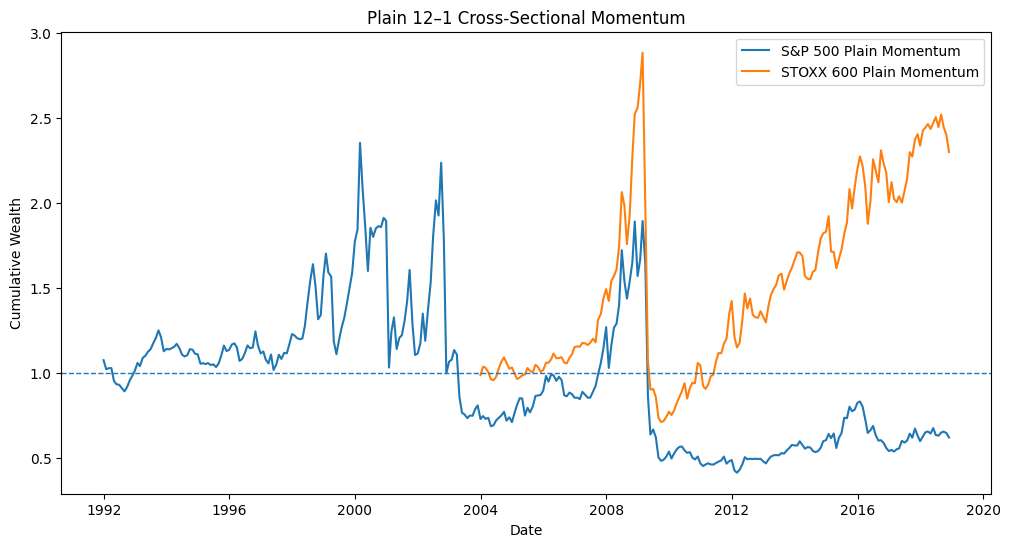

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    spx_plain_wealth.index,
    spx_plain_wealth,
    label="S&P 500 Plain Momentum"
)

plt.plot(
    stoxx_plain_wealth.index,
    stoxx_plain_wealth,
    label="STOXX 600 Plain Momentum"
)

plt.axhline(1, linestyle="--", linewidth=1)

plt.title(
    "Plain 12–1 Cross-Sectional Momentum"
)
plt.ylabel("Cumulative Wealth")
plt.xlabel("Date")
plt.legend()

plt.show()

### Interpretation

The plain cross-sectional momentum strategy exhibits substantial time variation in performance.

In both markets, momentum experiences periods of strong cumulative growth, but also
severe drawdowns, especially around major market stress episodes.

This confirms that the plain momentum strategy may offer attractive performance,
but it also carries significant crash risk.

For this reason, the next step of the analysis is not simply to look at cumulative
returns, but to measure the strategy's risk profile more formally using performance
statistics such as annualized return, volatility, Sharpe ratio, and maximum drawdown.

---


# 3. Understanding the Risk of Plain Momentum

## Objective

Before introducing any risk-control technique, we first evaluate the performance
and risk profile of the plain momentum strategy.

This step is essential because the purpose of volatility targeting is not to
change the momentum signal itself, but to improve the way risk is managed.

Therefore, we first need to understand:

- how profitable the plain strategy is;
- how volatile it is;
- how severe its drawdowns are;
- how extreme its worst losses can be.

## Performance metrics

We evaluate each strategy using complementary return and risk measures.

### 1. Annualized return
Throughout the notebook, this is the arithmetic mean monthly return multiplied by 12:

$$
\bar{R}_{ann} = 12\,\bar{R}_{month}
$$

It is useful for the Sharpe-ratio calculation, but it is not the same as compound growth.

### 2. CAGR
The compound annual growth rate measures the annual rate that links initial and final
wealth after accounting for compounding:

$$
CAGR = W_T^{12/N}-1
$$

where \(N\) is the number of monthly observations.

### 3. Annualized volatility
Monthly return volatility is annualized by multiplying the monthly standard deviation
by \(\sqrt{12}\).

### 4. Sharpe ratio
The Sharpe ratio measures return per unit of volatility. For consistency across the
long-short strategies and benchmarks, the notebook reports the Sharpe ratio under
the simplifying assumption \(R_f=0\).

### 5. Maximum drawdown
This measures the largest peak-to-trough loss in cumulative wealth and is especially
important because momentum strategies can experience severe crash episodes.

### 6. Worst month
The most negative monthly return observed in the sample.

### 7. Worst 3 months
The most negative rolling three-month compounded return.


In [ ]:
def compute_performance_metrics(return_series):

    r = return_series.dropna().copy()

    if len(r) == 0:
        return pd.Series({
            "Annualized Return": np.nan,
            "CAGR": np.nan,
            "Annualized Volatility": np.nan,
            "Sharpe Ratio": np.nan,
            "Maximum Drawdown": np.nan,
            "Worst Month": np.nan,
            "Worst 3 Months": np.nan,
            "Number of Months": 0
        })

    # Arithmetic annualized mean return
    ann_return = r.mean() * 12

    # Cumulative wealth
    wealth = (1 + r).cumprod()

    # CAGR
    years = len(r) / 12

    if wealth.iloc[-1] > 0:
        cagr = wealth.iloc[-1] ** (1 / years) - 1
    else:
        cagr = np.nan

    # Annualized volatility
    ann_vol = r.std() * np.sqrt(12)

    # Sharpe ratio
    sharpe = ann_return / ann_vol if ann_vol != 0 else np.nan

    # Drawdown
    running_peak = wealth.cummax()
    drawdown = wealth / running_peak - 1
    max_drawdown = drawdown.min()

    # Worst month
    worst_month = r.min()

    # Worst 3-month cumulative return
    rolling_3m = (
        (1 + r)
        .rolling(3)
        .apply(np.prod, raw=True)
        - 1
    )

    worst_3m = rolling_3m.min()

    return pd.Series({
        "Annualized Return": ann_return,
        "CAGR": cagr,
        "Annualized Volatility": ann_vol,
        "Sharpe Ratio": sharpe,
        "Maximum Drawdown": max_drawdown,
        "Worst Month": worst_month,
        "Worst 3 Months": worst_3m,
        "Number of Months": len(r)
    })

In [ ]:
spx_plain_stats = compute_performance_metrics(
    spx_plain_momentum["Long_Short"]
)

stoxx_plain_stats = compute_performance_metrics(
    stoxx_plain_momentum["Long_Short"]
)

plain_stats_table = pd.concat(
    [spx_plain_stats, stoxx_plain_stats],
    axis=1
)

plain_stats_table.columns = [
    "S&P 500 Plain Momentum",
    "STOXX 600 Plain Momentum"
]

plain_stats_table

,S&P 500 Plain Momentum,STOXX 600 Plain Momentum
Annualized Return,0.029140,0.087538
CAGR,-0.017528,0.057090
Annualized Volatility,0.286187,0.236057
Sharpe Ratio,0.101821,0.370832
Maximum Drawdown,-0.824713,-0.753553
Worst Month,-0.473027,-0.456703
Worst 3 Months,-0.663319,-0.687264
Number of Months,324.000000,180.000000


### Interpretation of the performance table

The table should be read jointly rather than focusing on a single statistic.

- annualized return describes average performance;
- CAGR describes actual compound wealth growth;
- volatility measures instability;
- Sharpe measures return relative to volatility under the \(R_f=0\) assumption;
- maximum drawdown captures peak-to-trough losses;
- worst-month and worst-three-month returns capture short-horizon tail risk.

This distinction is important because a strategy can have a positive arithmetic
average return but a negative CAGR when volatility and crash losses are sufficiently large.


In [ ]:
def compute_drawdown_series(return_series):

    r = return_series.dropna().copy()
    wealth = (1 + r).cumprod()
    running_peak = wealth.cummax()
    drawdown = wealth / running_peak - 1

    return drawdown

In [ ]:
spx_plain_drawdown = compute_drawdown_series(
    spx_plain_momentum["Long_Short"]
)

stoxx_plain_drawdown = compute_drawdown_series(
    stoxx_plain_momentum["Long_Short"]
)

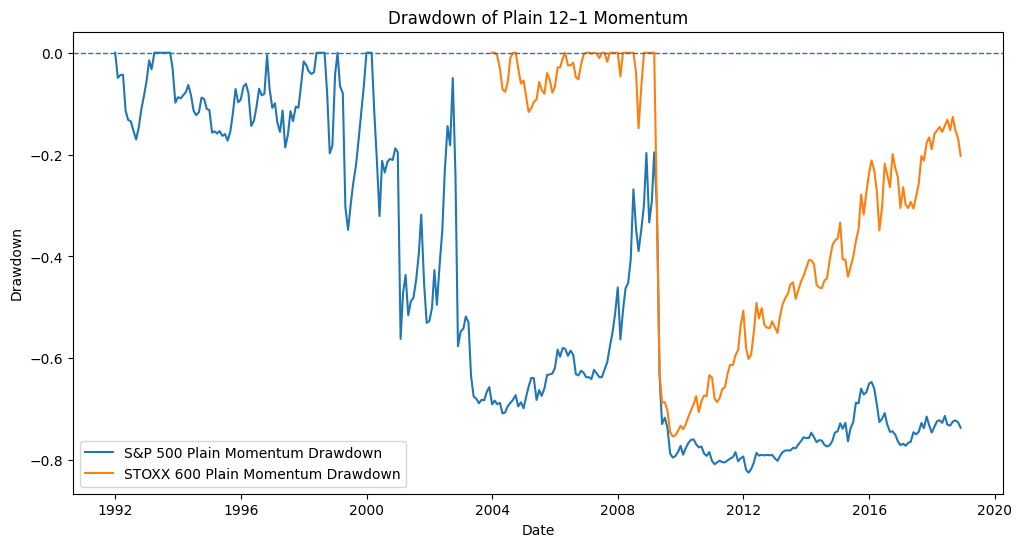

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    spx_plain_drawdown.index,
    spx_plain_drawdown,
    label="S&P 500 Plain Momentum Drawdown"
)

plt.plot(
    stoxx_plain_drawdown.index,
    stoxx_plain_drawdown,
    label="STOXX 600 Plain Momentum Drawdown"
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("Drawdown of Plain 12–1 Momentum")
plt.ylabel("Drawdown")
plt.xlabel("Date")
plt.legend()

plt.show()

### Interpretation of the drawdown chart

This chart highlights the downside risk of the plain momentum strategy.

Unlike cumulative wealth, which emphasizes long-run growth, drawdowns show how
deep the strategy falls below its previous peak.

Large negative drawdowns indicate that even if the strategy performs well over
the long run, it may still expose the investor to very painful crash episodes.

This is exactly the type of risk that volatility targeting is designed to mitigate.

In [ ]:
def worst_months_table(return_series, n=10):

    r = return_series.dropna().sort_values()
    worst = r.head(n).to_frame(name="Return")
    worst.index.name = "Date"

    return worst

In [ ]:
spx_worst_months = worst_months_table(
    spx_plain_momentum["Long_Short"],
    n=10
)

stoxx_worst_months = worst_months_table(
    stoxx_plain_momentum["Long_Short"],
    n=10
)

print("Worst 10 months - S&P 500 Plain Momentum")
display(spx_worst_months)

print("Worst 10 months - STOXX 600 Plain Momentum")
display(stoxx_worst_months)

Worst 10 months - S&P 500 Plain Momentum


,Return
Date,
2009-04-30,-0.473027
2001-01-31,-0.455573
2002-11-29,-0.441590
2009-05-29,-0.261388
1999-04-30,-0.243237
2003-04-30,-0.224514
2002-10-31,-0.201512
2001-10-31,-0.198252
2009-08-31,-0.191354


Worst 10 months - STOXX 600 Plain Momentum


,Return
Date,
2009-04-30,-0.456703
2009-03-31,-0.317546
2009-05-29,-0.156534
2012-01-31,-0.147538
2009-08-31,-0.141934
2011-01-31,-0.114967
2008-08-29,-0.113428
2015-02-27,-0.108190
2016-04-29,-0.105343


---


# 4. Volatility Targeting

## Motivation

The plain momentum strategy may experience periods of extremely high risk and
large drawdowns.

Volatility targeting is a risk-management technique that adjusts the exposure
of the strategy according to its recent realised volatility.

The basic intuition is:

> when recent volatility is high, reduce exposure;
> when recent volatility is low, exposure can be increased.

Importantly, volatility targeting does not change which securities are classified
as winners or losers.

It only changes the size of the overall momentum position.

## Estimating recent momentum volatility

The volatility forecast is based on the realised volatility of the plain momentum
strategy over the previous six months.

Monthly volatility is annualized as:

$$
\hat{\sigma}_{t-1}
=
\sigma_{monthly}\sqrt{12}
$$

Only information available before month \(t\) is used.

Therefore, the volatility estimate used to determine exposure in month \(t\)
must be based on returns observed up to month \(t-1\).

This one-month lag is necessary to avoid look-ahead bias.

## Volatility scaling rule

The exposure multiplier is defined as:

$$
c_t =
\frac{\sigma^{target}}
{\hat{\sigma}_{t-1}}
$$

where:

- \(\sigma^{target}\) is the desired annual volatility;
- \(\hat{\sigma}_{t-1}\) is the volatility estimated using past information.

If realised volatility is above the target, exposure is reduced.

If realised volatility is below the target, the unconstrained rule would increase
exposure.

The volatility-targeted strategy return is:

$$
R^{VT}_t = c_t R^{MOM}_t
$$

## Two volatility-targeting specifications

We compare two risk-scaling rules.

### Standard volatility targeting

$$
c^{STD}_t =
\min
\left(
2,
\frac{0.10}{\hat{\sigma}_{t-1}}
\right)
$$

Exposure can increase up to twice the baseline level when recent volatility is low.

### No-additional-leverage volatility targeting

$$
c^{NL}_t =
\min
\left(
1,
\frac{0.10}{\hat{\sigma}_{t-1}}
\right)
$$

This version can reduce exposure when risk is high but never increases exposure
above the original momentum position.

The term "no-leverage" refers to the scaling factor: the underlying momentum
portfolio itself remains a long-short portfolio.


In [ ]:
TARGET_VOL = 0.10
VOL_WINDOW = 6


def apply_volatility_targeting(
    strategy_returns,
    target_vol=0.10,
    vol_window=6,
    max_scaling=2.0
):

    r = strategy_returns.copy()

    # Step 1: estimate realised annualized volatility
    realised_vol = (
        r.rolling(
            window=vol_window,
            min_periods=vol_window
        ).std()
        * np.sqrt(12)
    )

    # Step 2: use only volatility information known before month t
    forecast_vol = realised_vol.shift(1)

    # Step 3: determine the exposure multiplier
    scaling_factor = target_vol / forecast_vol

    # Do not allow negative exposure and impose the maximum scaling
    scaling_factor = scaling_factor.clip(
        lower=0,
        upper=max_scaling
    )

    # Step 4: apply the exposure multiplier to the momentum return
    vt_return = scaling_factor * r

    output = pd.DataFrame({
        "Plain_Momentum": r,
        "Forecast_Volatility": forecast_vol,
        "Scaling_Factor": scaling_factor,
        "VT_Return": vt_return
    })

    return output

### Explanation of the volatility-targeting function

The function performs four steps.

**Step 1 — Estimate recent risk**

A rolling six-month standard deviation of plain momentum returns is calculated
and annualized.

**Step 2 — Lag the volatility estimate**

The volatility measure is shifted by one month so that exposure in month \(t\)
depends only on information available before month \(t\).

**Step 3 — Calculate the scaling factor**

$$
c_t =
\frac{0.10}{\hat{\sigma}_{t-1}}
$$

The factor is capped according to the chosen strategy.

**Step 4 — Scale momentum returns**

$$
R^{VT}_t =
c_t R^{MOM}_t
$$

Therefore, the underlying momentum signal remains unchanged: only portfolio
exposure is modified.

In [ ]:
spx_vt_standard = apply_volatility_targeting(
    strategy_returns=spx_plain_momentum["Long_Short"],
    target_vol=TARGET_VOL,
    vol_window=VOL_WINDOW,
    max_scaling=2.0
)

stoxx_vt_standard = apply_volatility_targeting(
    strategy_returns=stoxx_plain_momentum["Long_Short"],
    target_vol=TARGET_VOL,
    vol_window=VOL_WINDOW,
    max_scaling=2.0
)

In [ ]:
spx_vt_no_leverage = apply_volatility_targeting(
    strategy_returns=spx_plain_momentum["Long_Short"],
    target_vol=TARGET_VOL,
    vol_window=VOL_WINDOW,
    max_scaling=1.0
)

stoxx_vt_no_leverage = apply_volatility_targeting(
    strategy_returns=stoxx_plain_momentum["Long_Short"],
    target_vol=TARGET_VOL,
    vol_window=VOL_WINDOW,
    max_scaling=1.0
)

In [ ]:
print("S&P 500 - Standard VT")
display(
    spx_vt_standard[
        ["Forecast_Volatility", "Scaling_Factor"]
    ].describe()
)

print("S&P 500 - No-Leverage VT")
display(
    spx_vt_no_leverage[
        ["Forecast_Volatility", "Scaling_Factor"]
    ].describe()
)

S&P 500 - Standard VT


,Forecast_Volatility,Scaling_Factor
count,318.000000,318.000000
mean,0.224942,0.708361
std,0.177747,0.447425
min,0.030425,0.117969
25%,0.107357,0.327269
50%,0.155702,0.642274
75%,0.305626,0.931470
max,0.847681,2.000000


S&P 500 - No-Leverage VT


,Forecast_Volatility,Scaling_Factor
count,318.000000,318.000000
mean,0.224942,0.625111
std,0.177747,0.297813
min,0.030425,0.117969
25%,0.107357,0.327269
50%,0.155702,0.642274
75%,0.305626,0.931470
max,0.847681,1.000000


In [ ]:
print("STOXX 600 - Standard VT")
display(
    stoxx_vt_standard[
        ["Forecast_Volatility", "Scaling_Factor"]
    ].describe()
)

print("STOXX 600 - No-Leverage VT")
display(
    stoxx_vt_no_leverage[
        ["Forecast_Volatility", "Scaling_Factor"]
    ].describe()
)

STOXX 600 - Standard VT


,Forecast_Volatility,Scaling_Factor
count,174.000000,174.000000
mean,0.181761,0.786217
std,0.134738,0.429689
min,0.035978,0.121277
25%,0.099177,0.444888
50%,0.132597,0.754184
75%,0.224795,1.008295
max,0.824556,2.000000


STOXX 600 - No-Leverage VT


,Forecast_Volatility,Scaling_Factor
count,174.000000,174.000000
mean,0.181761,0.691928
std,0.134738,0.278744
min,0.035978,0.121277
25%,0.099177,0.444888
50%,0.132597,0.754184
75%,0.224795,1.000000
max,0.824556,1.000000


### Interpretation

Before evaluating performance, it is useful to verify how the risk-management
rule actually changes exposure.

A scaling factor:

- below 1 means that exposure is reduced;
- equal to 1 means that baseline exposure is maintained;
- above 1 means that additional exposure is taken.

Only the standard volatility-targeting strategy is allowed to have a scaling
factor above 1.

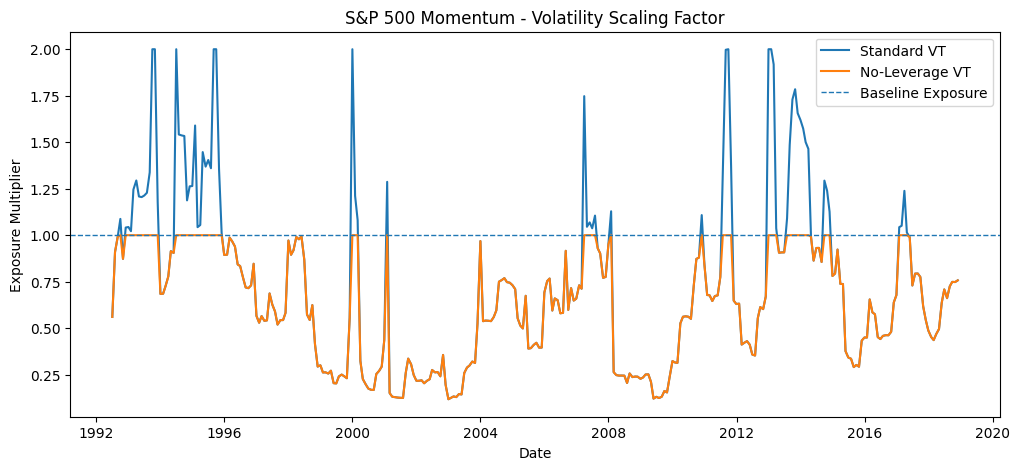

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    spx_vt_standard.index,
    spx_vt_standard["Scaling_Factor"],
    label="Standard VT"
)

plt.plot(
    spx_vt_no_leverage.index,
    spx_vt_no_leverage["Scaling_Factor"],
    label="No-Leverage VT"
)

plt.axhline(
    1,
    linestyle="--",
    linewidth=1,
    label="Baseline Exposure"
)

plt.title("S&P 500 Momentum - Volatility Scaling Factor")
plt.ylabel("Exposure Multiplier")
plt.xlabel("Date")
plt.legend()

plt.show()

### Interpretation

The scaling factor shows how aggressively the volatility-targeting strategy
adjusts exposure through time.

When the factor falls below 1, the strategy is reducing risk because recent
momentum volatility is high.

When the standard strategy rises above 1, it is increasing exposure because
recent volatility is below the 10% target.

The no-leverage version is capped at 1 and therefore never increases exposure
above the original momentum portfolio.

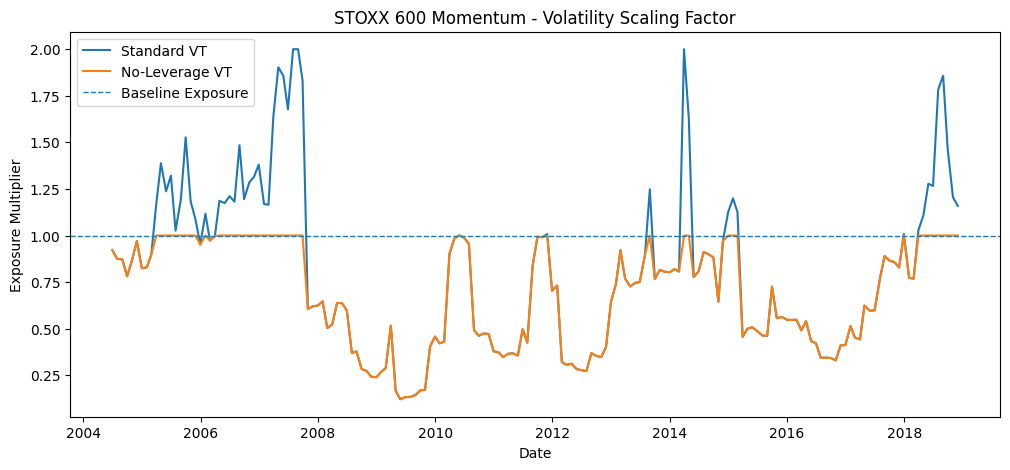

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    stoxx_vt_standard.index,
    stoxx_vt_standard["Scaling_Factor"],
    label="Standard VT"
)

plt.plot(
    stoxx_vt_no_leverage.index,
    stoxx_vt_no_leverage["Scaling_Factor"],
    label="No-Leverage VT"
)

plt.axhline(
    1,
    linestyle="--",
    linewidth=1,
    label="Baseline Exposure"
)

plt.title("STOXX 600 Momentum - Volatility Scaling Factor")
plt.ylabel("Exposure Multiplier")
plt.xlabel("Date")
plt.legend()

plt.show()

In [ ]:
spx_strategy_comparison = pd.concat(
    [
        spx_plain_momentum["Long_Short"].rename("Plain Momentum"),
        spx_vt_standard["VT_Return"].rename("Standard VT"),
        spx_vt_no_leverage["VT_Return"].rename("No-Leverage VT")
    ],
    axis=1
).dropna()

stoxx_strategy_comparison = pd.concat(
    [
        stoxx_plain_momentum["Long_Short"].rename("Plain Momentum"),
        stoxx_vt_standard["VT_Return"].rename("Standard VT"),
        stoxx_vt_no_leverage["VT_Return"].rename("No-Leverage VT")
    ],
    axis=1
).dropna()

## Fair comparison across strategies

Volatility targeting requires an initial estimation window before the first
scaling factor can be calculated.

For this reason, plain momentum has a slightly longer available history than
the volatility-targeted strategies.

To ensure a fair comparison, all three strategies are evaluated over the same
common sample within each market.

This avoids attributing performance differences to different sample periods.

In [ ]:
spx_comparison_stats = pd.DataFrame({
    col: compute_performance_metrics(
        spx_strategy_comparison[col]
    )
    for col in spx_strategy_comparison.columns
}).T

spx_comparison_stats

,Annualized Return,CAGR,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Worst Month,Worst 3 Months,Number of Months
Plain Momentum,0.032034,-0.015291,0.287947,0.111249,-0.824713,-0.473027,-0.663319,318.0
Standard VT,0.034740,0.012733,0.187870,0.184914,-0.653149,-0.586243,-0.584422,318.0
No-Leverage VT,0.026678,0.012538,0.158113,0.168730,-0.543610,-0.455573,-0.453178,318.0


In [ ]:
stoxx_comparison_stats = pd.DataFrame({
    col: compute_performance_metrics(
        stoxx_strategy_comparison[col]
    )
    for col in stoxx_strategy_comparison.columns
}).T

stoxx_comparison_stats

,Annualized Return,CAGR,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Worst Month,Worst 3 Months,Number of Months
Plain Momentum,0.093405,0.062327,0.239226,0.390448,-0.753553,-0.456703,-0.687264,174.0
Standard VT,0.091342,0.084690,0.140044,0.652239,-0.266644,-0.163962,-0.242099,174.0
No-Leverage VT,0.085584,0.080647,0.124125,0.689501,-0.266644,-0.163962,-0.242099,174.0


In [ ]:
percentage_columns = [
    "Annualized Return",
    "CAGR",
    "Annualized Volatility",
    "Maximum Drawdown",
    "Worst Month",
    "Worst 3 Months"
]

spx_display = spx_comparison_stats.copy()
stoxx_display = stoxx_comparison_stats.copy()

for col in percentage_columns:
    spx_display[col] = (
        spx_display[col] * 100
    ).round(2)

    stoxx_display[col] = (
        stoxx_display[col] * 100
    ).round(2)

spx_display["Sharpe Ratio"] = (
    spx_display["Sharpe Ratio"].round(2)
)

stoxx_display["Sharpe Ratio"] = (
    stoxx_display["Sharpe Ratio"].round(2)
)

print("S&P 500")
display(spx_display)

print("STOXX 600")
display(stoxx_display)

S&P 500


,Annualized Return,CAGR,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Worst Month,Worst 3 Months,Number of Months
Plain Momentum,3.20,-1.53,28.79,0.11,-82.47,-47.30,-66.33,318.0
Standard VT,3.47,1.27,18.79,0.18,-65.31,-58.62,-58.44,318.0
No-Leverage VT,2.67,1.25,15.81,0.17,-54.36,-45.56,-45.32,318.0


STOXX 600


,Annualized Return,CAGR,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Worst Month,Worst 3 Months,Number of Months
Plain Momentum,9.34,6.23,23.92,0.39,-75.36,-45.67,-68.73,174.0
Standard VT,9.13,8.47,14.00,0.65,-26.66,-16.40,-24.21,174.0
No-Leverage VT,8.56,8.06,12.41,0.69,-26.66,-16.40,-24.21,174.0


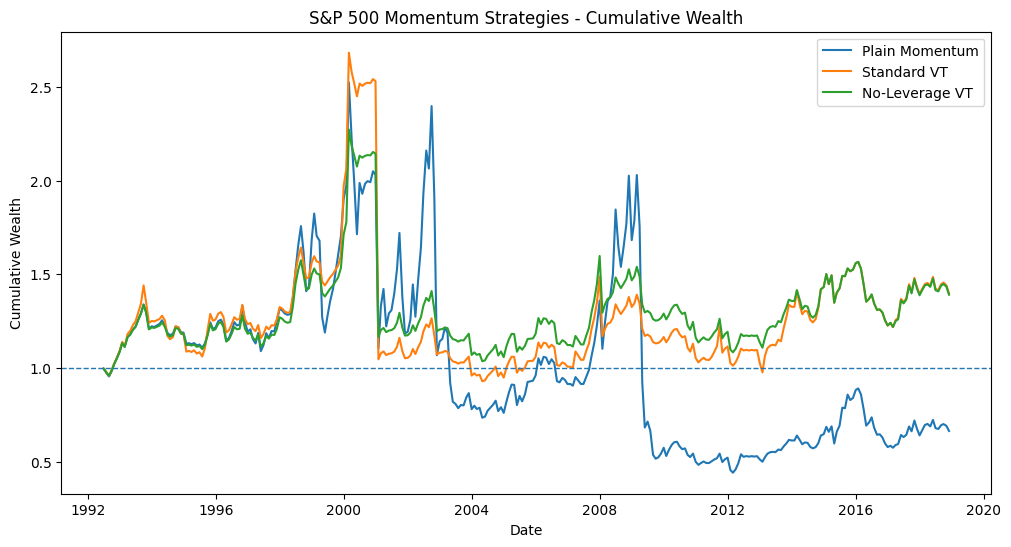

In [ ]:
spx_wealth_comparison = (
    1 + spx_strategy_comparison
).cumprod()

plt.figure(figsize=(12, 6))

for column in spx_wealth_comparison.columns:

    plt.plot(
        spx_wealth_comparison.index,
        spx_wealth_comparison[column],
        label=column
    )

plt.axhline(1, linestyle="--", linewidth=1)

plt.title(
    "S&P 500 Momentum Strategies - Cumulative Wealth"
)

plt.ylabel("Cumulative Wealth")
plt.xlabel("Date")
plt.legend()

plt.show()

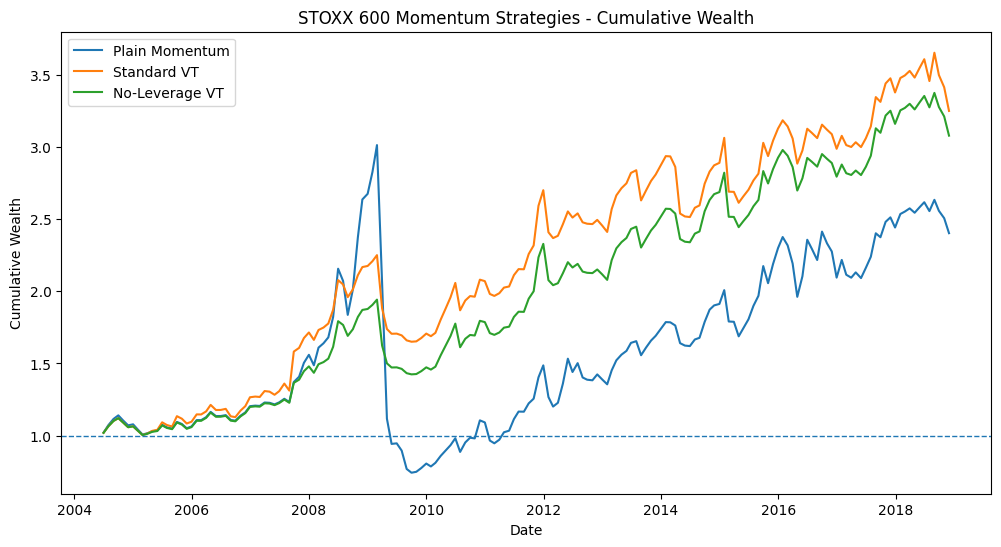

In [ ]:
stoxx_wealth_comparison = (
    1 + stoxx_strategy_comparison
).cumprod()

plt.figure(figsize=(12, 6))

for column in stoxx_wealth_comparison.columns:

    plt.plot(
        stoxx_wealth_comparison.index,
        stoxx_wealth_comparison[column],
        label=column
    )

plt.axhline(1, linestyle="--", linewidth=1)

plt.title(
    "STOXX 600 Momentum Strategies - Cumulative Wealth"
)

plt.ylabel("Cumulative Wealth")
plt.xlabel("Date")
plt.legend()

plt.show()

## Baseline volatility-targeting results

The baseline results show that volatility targeting primarily improves the **risk
profile** of momentum rather than its arithmetic average return.

In the S&P 500 sample, annualized volatility falls from 28.79% for Plain Momentum
to 18.79% for Standard VT and 15.81% for No-Leverage VT. Maximum drawdown improves
from -82.47% to -65.31% and -54.36%, respectively.

However, Standard VT has a worse single month (-58.62%) than Plain Momentum
(-47.30%). This is the first indication that leverage can amplify a sudden crash
when the volatility estimate is low before the shock.

In the STOXX 600 sample, both VT specifications reduce volatility and drawdown
substantially. Standard VT raises CAGR from 6.23% for Plain Momentum to 8.47%
despite a slightly lower arithmetic average return, illustrating the importance
of lower volatility for compounding.


---


# 5. Anatomy of Momentum Crashes

## Objective

The previous analysis showed that plain momentum can experience very large losses,
while volatility targeting substantially reduces average volatility and drawdowns.

However, the S&P 500 results also revealed an important exception:
the standard volatility-targeted strategy experienced a worse single-month loss
than plain momentum.

This section therefore investigates the anatomy of momentum crashes.

For the worst months of the plain momentum strategy, we examine:

- the return of the winner portfolio;
- the return of the loser portfolio;
- the resulting long-short momentum return;
- the volatility estimated before the crash;
- the exposure multiplier chosen by volatility targeting;
- the return of Standard VT;
- the return of No-Leverage VT.

The goal is to understand not only how much momentum loses,
but why the loss occurs and whether risk scaling mitigates or amplifies it.

## Where can a momentum crash come from?

The long-short momentum return is:

$$
R^{MOM}_t =
R^{Winners}_t - R^{Losers}_t
$$

A large negative momentum return can therefore arise through two mechanisms.

### Winner collapse

The securities held in the long portfolio experience very poor returns.

### Loser rebound

Past losers suddenly experience very strong positive returns.

Because the momentum strategy is short these securities, a large loser rebound
can generate severe losses for the long-short portfolio.

Separating the two legs allows us to understand the economic mechanism behind
each momentum crash.

## Definition of crash months

For the descriptive crash analysis, we define crash months as the ten worst
monthly returns of the plain momentum strategy in each market.

This rule is applied mechanically rather than selecting individual historical
episodes by hand.

The purpose is not to propose a formal statistical definition of a momentum crash,
but to identify the most severe realised losses in the sample for diagnostic analysis.

In [ ]:
def build_crash_table(
    plain_momentum,
    vt_standard,
    vt_no_leverage,
    n_worst=10
):

    # Select the n worst months of plain momentum
    crash_dates = (
        plain_momentum["Long_Short"]
        .dropna()
        .nsmallest(n_worst)
        .index
    )

    crash_table = pd.DataFrame(index=crash_dates)

    # Long and short portfolio returns
    crash_table["Winners_Return"] = (
        plain_momentum.loc[crash_dates, "Long"]
    )

    crash_table["Losers_Return"] = (
        plain_momentum.loc[crash_dates, "Short_Leg"]
    )

    # Contribution of the short position
    crash_table["Short_Contribution"] = (
        -crash_table["Losers_Return"]
    )

    # Plain momentum
    crash_table["Plain_Momentum"] = (
        plain_momentum.loc[crash_dates, "Long_Short"]
    )

    # Information known before the crash month
    crash_table["Forecast_Volatility"] = (
        vt_standard.loc[
            crash_dates,
            "Forecast_Volatility"
        ]
    )

    # Standard VT exposure
    crash_table["Standard_Scaling"] = (
        vt_standard.loc[
            crash_dates,
            "Scaling_Factor"
        ]
    )

    # No-leverage VT exposure
    crash_table["NoLev_Scaling"] = (
        vt_no_leverage.loc[
            crash_dates,
            "Scaling_Factor"
        ]
    )

    # Strategy returns during the crash
    crash_table["Standard_VT"] = (
        vt_standard.loc[
            crash_dates,
            "VT_Return"
        ]
    )

    crash_table["NoLeverage_VT"] = (
        vt_no_leverage.loc[
            crash_dates,
            "VT_Return"
        ]
    )

    # Sort from worst plain momentum crash to least severe
    crash_table = crash_table.sort_values(
        "Plain_Momentum"
    )

    return crash_table

### Explanation

The function first identifies the ten worst months of the plain momentum strategy.

For exactly those same dates, it retrieves:

- the winner portfolio return;
- the loser portfolio return;
- the contribution of the short position;
- the plain momentum return;
- the volatility estimate available before the month;
- the exposure multiplier selected by each volatility-targeting rule;
- the realised returns of Standard VT and No-Leverage VT.

Using the same crash dates for all strategies ensures that we are comparing
their behaviour during identical stress episodes.

In [ ]:
spx_crash_table = build_crash_table(
    plain_momentum=spx_plain_momentum,
    vt_standard=spx_vt_standard,
    vt_no_leverage=spx_vt_no_leverage,
    n_worst=10
)

stoxx_crash_table = build_crash_table(
    plain_momentum=stoxx_plain_momentum,
    vt_standard=stoxx_vt_standard,
    vt_no_leverage=stoxx_vt_no_leverage,
    n_worst=10
)

In [ ]:
print("S&P 500 - Worst Plain Momentum Months")
display(spx_crash_table)

print("STOXX 600 - Worst Plain Momentum Months")
display(stoxx_crash_table)

S&P 500 - Worst Plain Momentum Months


,Winners_Return,Losers_Return,Short_Contribution,Plain_Momentum,Forecast_Volatility,Standard_Scaling,NoLev_Scaling,Standard_VT,NoLeverage_VT
date,,,,,,,,,
2009-04-30,0.008630,0.481657,-0.481657,-0.473027,0.474336,0.210821,0.210821,-0.099724,-0.099724
2001-01-31,-0.069381,0.386192,-0.386192,-0.455573,0.077711,1.286825,1.000000,-0.586243,-0.455573
2002-11-29,-0.030688,0.410902,-0.410902,-0.441590,0.511473,0.195514,0.195514,-0.086337,-0.086337
2009-05-29,-0.043223,0.218165,-0.218165,-0.261388,0.823625,0.121414,0.121414,-0.031736,-0.031736
1999-04-30,-0.013778,0.229459,-0.229459,-0.243237,0.368470,0.271392,0.271392,-0.066013,-0.066013
2003-04-30,0.030062,0.254576,-0.254576,-0.224514,0.686254,0.145719,0.145719,-0.032716,-0.032716
2002-10-31,0.002917,0.204429,-0.204429,-0.201512,0.280828,0.356090,0.356090,-0.071756,-0.071756
2001-10-31,-0.020621,0.177631,-0.177631,-0.198252,0.326706,0.306085,0.306085,-0.060682,-0.060682
2009-08-31,0.021757,0.213111,-0.213111,-0.191354,0.760014,0.131577,0.131577,-0.025178,-0.025178


STOXX 600 - Worst Plain Momentum Months


,Winners_Return,Losers_Return,Short_Contribution,Plain_Momentum,Forecast_Volatility,Standard_Scaling,NoLev_Scaling,Standard_VT,NoLeverage_VT
date,,,,,,,,,
2009-04-30,0.032368,0.489072,-0.489072,-0.456703,0.601570,0.166232,0.166232,-0.075919,-0.075919
2009-03-31,-0.026398,0.291148,-0.291148,-0.317546,0.193671,0.516340,0.516340,-0.163962,-0.163962
2009-05-29,-0.002612,0.153922,-0.153922,-0.156534,0.824556,0.121277,0.121277,-0.018984,-0.018984
2012-01-31,0.001924,0.149462,-0.149462,-0.147538,0.136636,0.731873,0.731873,-0.107979,-0.107979
2009-08-31,0.009996,0.151930,-0.151930,-0.141934,0.695836,0.143712,0.143712,-0.020398,-0.020398
2011-01-31,-0.030122,0.084845,-0.084845,-0.114967,0.268060,0.373051,0.373051,-0.042889,-0.042889
2008-08-29,-0.003729,0.109699,-0.109699,-0.113428,0.264517,0.378048,0.378048,-0.042881,-0.042881
2015-02-27,0.046525,0.154716,-0.154716,-0.108190,0.088858,1.125397,1.000000,-0.121757,-0.108190
2016-04-29,-0.018938,0.086406,-0.086406,-0.105343,0.185141,0.540130,0.540130,-0.056899,-0.056899


In [ ]:
def format_crash_table(table):

    formatted = table.copy()

    percentage_columns = [
        "Winners_Return",
        "Losers_Return",
        "Short_Contribution",
        "Plain_Momentum",
        "Forecast_Volatility",
        "Standard_VT",
        "NoLeverage_VT"
    ]

    for col in percentage_columns:
        formatted[col] = (
            formatted[col] * 100
        ).round(2)

    formatted["Standard_Scaling"] = (
        formatted["Standard_Scaling"]
        .round(2)
    )

    formatted["NoLev_Scaling"] = (
        formatted["NoLev_Scaling"]
        .round(2)
    )

    return formatted

In [ ]:
print("S&P 500")
display(
    format_crash_table(
        spx_crash_table
    )
)

print("STOXX 600")
display(
    format_crash_table(
        stoxx_crash_table
    )
)

S&P 500


,Winners_Return,Losers_Return,Short_Contribution,Plain_Momentum,Forecast_Volatility,Standard_Scaling,NoLev_Scaling,Standard_VT,NoLeverage_VT
date,,,,,,,,,
2009-04-30,0.86,48.17,-48.17,-47.30,47.43,0.21,0.21,-9.97,-9.97
2001-01-31,-6.94,38.62,-38.62,-45.56,7.77,1.29,1.00,-58.62,-45.56
2002-11-29,-3.07,41.09,-41.09,-44.16,51.15,0.20,0.20,-8.63,-8.63
2009-05-29,-4.32,21.82,-21.82,-26.14,82.36,0.12,0.12,-3.17,-3.17
1999-04-30,-1.38,22.95,-22.95,-24.32,36.85,0.27,0.27,-6.60,-6.60
2003-04-30,3.01,25.46,-25.46,-22.45,68.63,0.15,0.15,-3.27,-3.27
2002-10-31,0.29,20.44,-20.44,-20.15,28.08,0.36,0.36,-7.18,-7.18
2001-10-31,-2.06,17.76,-17.76,-19.83,32.67,0.31,0.31,-6.07,-6.07
2009-08-31,2.18,21.31,-21.31,-19.14,76.00,0.13,0.13,-2.52,-2.52


STOXX 600


,Winners_Return,Losers_Return,Short_Contribution,Plain_Momentum,Forecast_Volatility,Standard_Scaling,NoLev_Scaling,Standard_VT,NoLeverage_VT
date,,,,,,,,,
2009-04-30,3.24,48.91,-48.91,-45.67,60.16,0.17,0.17,-7.59,-7.59
2009-03-31,-2.64,29.11,-29.11,-31.75,19.37,0.52,0.52,-16.40,-16.40
2009-05-29,-0.26,15.39,-15.39,-15.65,82.46,0.12,0.12,-1.90,-1.90
2012-01-31,0.19,14.95,-14.95,-14.75,13.66,0.73,0.73,-10.80,-10.80
2009-08-31,1.00,15.19,-15.19,-14.19,69.58,0.14,0.14,-2.04,-2.04
2011-01-31,-3.01,8.48,-8.48,-11.50,26.81,0.37,0.37,-4.29,-4.29
2008-08-29,-0.37,10.97,-10.97,-11.34,26.45,0.38,0.38,-4.29,-4.29
2015-02-27,4.65,15.47,-15.47,-10.82,8.89,1.13,1.00,-12.18,-10.82
2016-04-29,-1.89,8.64,-8.64,-10.53,18.51,0.54,0.54,-5.69,-5.69


In [ ]:
def add_crash_diagnostics(crash_table):

    table = crash_table.copy()

    # Was Standard VT levered above the baseline?
    table["Standard_Levered"] = (
        table["Standard_Scaling"] > 1
    )

    # Did Standard VT produce a worse return than Plain Momentum?
    table["Standard_Worse_Than_Plain"] = (
        table["Standard_VT"]
        <
        table["Plain_Momentum"]
    )

    # Did No-Leverage VT improve the loss?
    table["NoLev_Better_Than_Plain"] = (
        table["NoLeverage_VT"]
        >
        table["Plain_Momentum"]
    )

    return table

In [ ]:
spx_crash_diagnostics = add_crash_diagnostics(
    spx_crash_table
)

stoxx_crash_diagnostics = add_crash_diagnostics(
    stoxx_crash_table
)

In [ ]:
display(
    spx_crash_diagnostics[
        [
            "Plain_Momentum",
            "Standard_Scaling",
            "Standard_VT",
            "NoLeverage_VT",
            "Standard_Levered",
            "Standard_Worse_Than_Plain",
            "NoLev_Better_Than_Plain"
        ]
    ]
)

,Plain_Momentum,Standard_Scaling,Standard_VT,NoLeverage_VT,Standard_Levered,Standard_Worse_Than_Plain,NoLev_Better_Than_Plain
date,,,,,,,
2009-04-30,-0.473027,0.210821,-0.099724,-0.099724,False,False,True
2001-01-31,-0.455573,1.286825,-0.586243,-0.455573,True,True,False
2002-11-29,-0.441590,0.195514,-0.086337,-0.086337,False,False,True
2009-05-29,-0.261388,0.121414,-0.031736,-0.031736,False,False,True
1999-04-30,-0.243237,0.271392,-0.066013,-0.066013,False,False,True
2003-04-30,-0.224514,0.145719,-0.032716,-0.032716,False,False,True
2002-10-31,-0.201512,0.356090,-0.071756,-0.071756,False,False,True
2001-10-31,-0.198252,0.306085,-0.060682,-0.060682,False,False,True
2009-08-31,-0.191354,0.131577,-0.025178,-0.025178,False,False,True


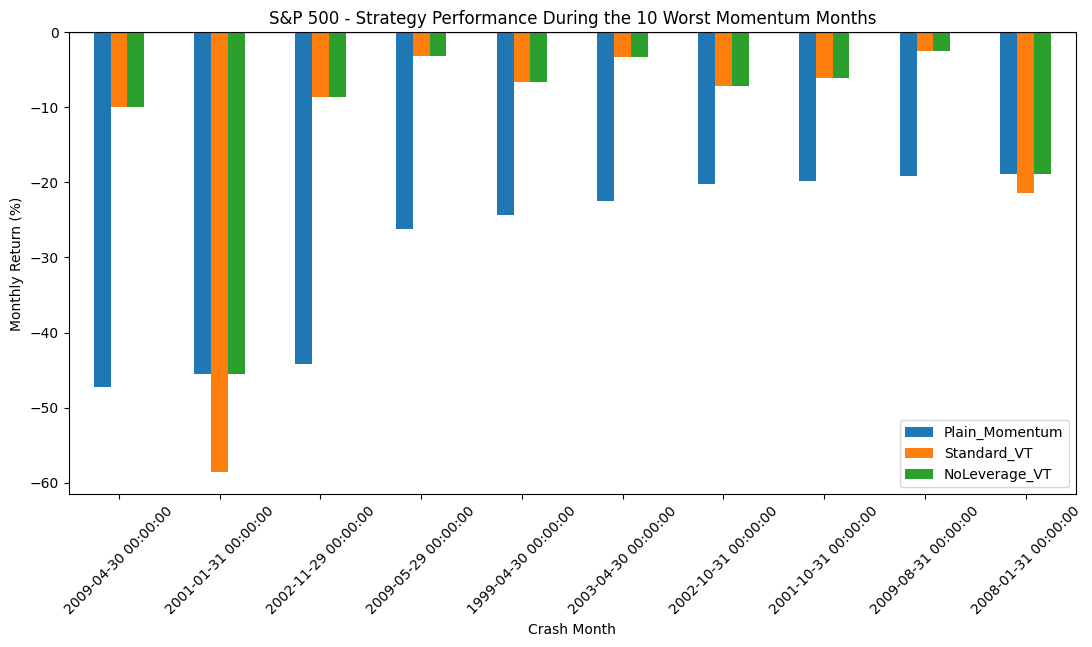

In [ ]:
spx_crash_returns = (
    spx_crash_table[
        [
            "Plain_Momentum",
            "Standard_VT",
            "NoLeverage_VT"
        ]
    ]
    * 100
)

spx_crash_returns.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title(
    "S&P 500 - Strategy Performance During the 10 Worst Momentum Months"
)

plt.ylabel("Monthly Return (%)")
plt.xlabel("Crash Month")
plt.axhline(0, linewidth=1)

plt.xticks(rotation=45)

plt.show()

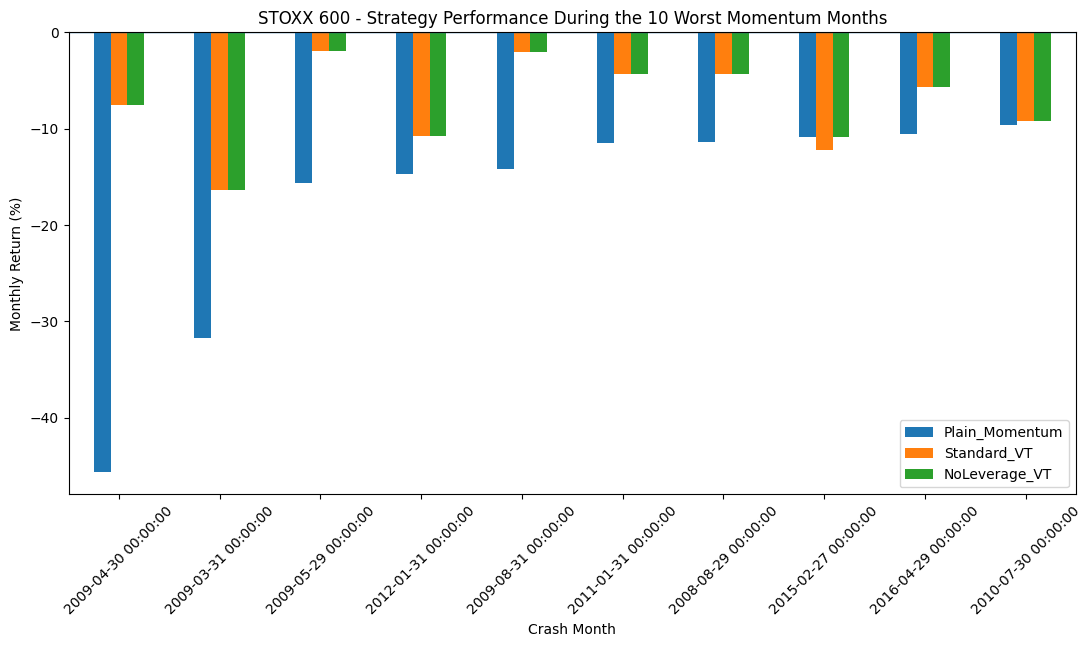

In [ ]:
stoxx_crash_returns = (
    stoxx_crash_table[
        [
            "Plain_Momentum",
            "Standard_VT",
            "NoLeverage_VT"
        ]
    ]
    * 100
)

stoxx_crash_returns.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title(
    "STOXX 600 - Strategy Performance During the 10 Worst Momentum Months"
)

plt.ylabel("Monthly Return (%)")
plt.xlabel("Crash Month")
plt.axhline(0, linewidth=1)

plt.xticks(rotation=45)

plt.show()

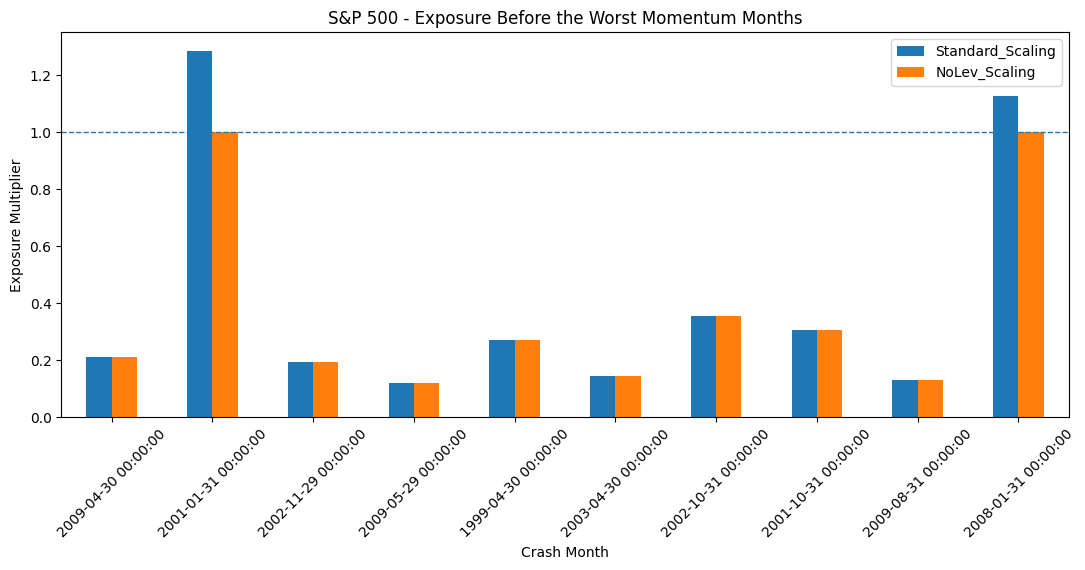

In [ ]:
(
    spx_crash_table[
        [
            "Standard_Scaling",
            "NoLev_Scaling"
        ]
    ]
    .plot(
        kind="bar",
        figsize=(13, 5)
    )
)

plt.axhline(
    1,
    linestyle="--",
    linewidth=1
)

plt.title(
    "S&P 500 - Exposure Before the Worst Momentum Months"
)

plt.ylabel("Exposure Multiplier")
plt.xlabel("Crash Month")

plt.xticks(rotation=45)

plt.show()

## Crash-analysis findings

The worst momentum months are predominantly associated with **sharp rebounds of
past losers**, which are harmful because the strategy is short those securities.

Among the ten worst Plain Momentum months, the short-leg contribution is the dominant
negative component in 9 out of 10 S&P 500 episodes and in all 10 STOXX 600 episodes.

Volatility targeting is most protective when volatility is already elevated before
the crash. For example, in April 2009 the S&P 500 forecast volatility was 47.43%,
so the scaling factor fell to 0.21 and the loss was reduced from -47.30% for Plain
Momentum to -9.97% for both VT specifications.

The opposite mechanism appears after calm periods. In January 2001, forecast
volatility was only 7.77%, Standard VT scaled exposure to 1.29, and the Plain
Momentum loss of -45.56% was amplified to -58.62%. No-Leverage VT stayed at a
scaling factor of 1 and therefore did not amplify the crash.

The evidence supports a conditional conclusion: volatility targeting can provide
strong crash protection when risk has already risen, but leverage introduces extra
tail risk when a sudden crash follows a low-volatility environment.


---


# 6. Cross-Market Robustness: S&P 500 vs STOXX 600

The same momentum and volatility-targeting specifications are applied to both
the S&P 500 and STOXX 600 datasets.

No parameters are changed across markets.

The purpose is to investigate whether the main conclusions are specific to the
U.S. sample or also appear in a different equity market.

In [ ]:
spx_cross_market = spx_comparison_stats.copy()
spx_cross_market["Market"] = "S&P 500"

stoxx_cross_market = stoxx_comparison_stats.copy()
stoxx_cross_market["Market"] = "STOXX 600"

cross_market_results = pd.concat(
    [
        spx_cross_market,
        stoxx_cross_market
    ]
)

cross_market_results = (
    cross_market_results
    .reset_index()
    .rename(columns={"index": "Strategy"})
    .set_index(["Market", "Strategy"])
)

cross_market_results

Annualized Return  ...  Number of Months
Market    Strategy                           ...                  
S&P 500   Plain Momentum           0.032034  ...             318.0
          Standard VT              0.034740  ...             318.0
          No-Leverage VT           0.026678  ...             318.0
STOXX 600 Plain Momentum           0.093405  ...             174.0
          Standard VT              0.091342  ...             174.0
          No-Leverage VT           0.085584  ...             174.0

[6 rows x 8 columns]

## Cross-market interpretation

The main qualitative findings are consistent across the two markets.

In both the S&P 500 and STOXX 600:

- plain momentum experiences high volatility and severe drawdowns;
- volatility targeting substantially reduces risk;
- lower volatility improves compound wealth growth;
- the no-additional-leverage specification is more defensive;
- standard volatility targeting can amplify sudden losses when a crash follows
  a low-volatility period.

This cross-market evidence suggests that the main risk-management mechanism is
not unique to the U.S. market.

However, the two datasets cover different historical periods. Therefore,
differences in absolute returns between the S&P 500 and STOXX 600 should not yet
be interpreted as evidence that momentum performs better in one market.

A common-sample comparison is required for a more direct comparison.

---


# 7. Common-Sample Comparison

The S&P 500 and STOXX 600 datasets cover different historical periods.

A direct comparison of their full-sample performance may therefore be affected
by different market environments.

To improve comparability, both markets are now evaluated over exactly the same
set of months.

No strategy parameters are changed. Only the evaluation period is restricted
to the intersection of the two available samples.

In [ ]:
common_dates = (
    spx_strategy_comparison.index
    .intersection(stoxx_strategy_comparison.index)
)

spx_common = spx_strategy_comparison.loc[common_dates].copy()
stoxx_common = stoxx_strategy_comparison.loc[common_dates].copy()

print("Common sample start:", common_dates.min())
print("Common sample end:", common_dates.max())
print("Number of common months:", len(common_dates))

Common sample start: 2004-06-30 00:00:00
Common sample end: 2018-11-30 00:00:00
Number of common months: 174


In [ ]:
spx_common_stats = pd.DataFrame({
    col: compute_performance_metrics(
        spx_common[col]
    )
    for col in spx_common.columns
}).T

stoxx_common_stats = pd.DataFrame({
    col: compute_performance_metrics(
        stoxx_common[col]
    )
    for col in stoxx_common.columns
}).T

In [ ]:
common_percentage_columns = [
    "Annualized Return",
    "CAGR",
    "Annualized Volatility",
    "Maximum Drawdown",
    "Worst Month",
    "Worst 3 Months"
]

spx_common_display = spx_common_stats.copy()
stoxx_common_display = stoxx_common_stats.copy()

for col in common_percentage_columns:

    spx_common_display[col] = (
        spx_common_display[col] * 100
    ).round(2)

    stoxx_common_display[col] = (
        stoxx_common_display[col] * 100
    ).round(2)

spx_common_display["Sharpe Ratio"] = (
    spx_common_display["Sharpe Ratio"].round(2)
)

stoxx_common_display["Sharpe Ratio"] = (
    stoxx_common_display["Sharpe Ratio"].round(2)
)

print("S&P 500 - Common Sample")
display(spx_common_display)

print("STOXX 600 - Common Sample")
display(stoxx_common_display)

S&P 500 - Common Sample


,Annualized Return,CAGR,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Worst Month,Worst 3 Months,Number of Months
Plain Momentum,2.91,-0.75,25.41,0.11,-78.21,-47.30,-66.33,174.0
Standard VT,3.78,2.82,13.90,0.27,-34.33,-21.35,-16.88,174.0
No-Leverage VT,2.81,2.02,12.55,0.22,-32.14,-18.92,-15.79,174.0


STOXX 600 - Common Sample


,Annualized Return,CAGR,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Worst Month,Worst 3 Months,Number of Months
Plain Momentum,9.34,6.23,23.92,0.39,-75.36,-45.67,-68.73,174.0
Standard VT,9.13,8.47,14.00,0.65,-26.66,-16.40,-24.21,174.0
No-Leverage VT,8.56,8.06,12.41,0.69,-26.66,-16.40,-24.21,174.0


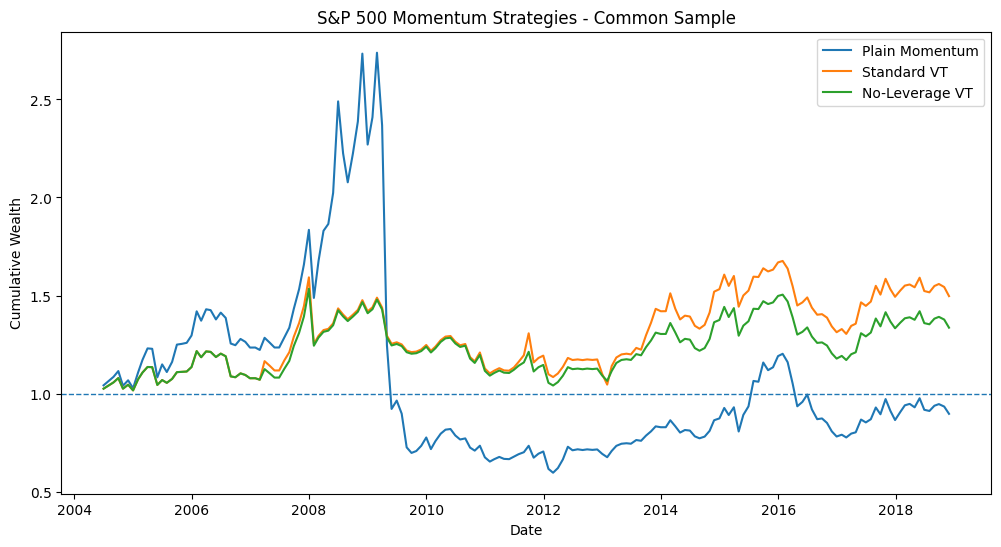

In [ ]:
spx_common_wealth = (
    1 + spx_common
).cumprod()

plt.figure(figsize=(12, 6))

for column in spx_common_wealth.columns:

    plt.plot(
        spx_common_wealth.index,
        spx_common_wealth[column],
        label=column
    )

plt.axhline(1, linestyle="--", linewidth=1)

plt.title(
    "S&P 500 Momentum Strategies - Common Sample"
)

plt.ylabel("Cumulative Wealth")
plt.xlabel("Date")
plt.legend()

plt.show()

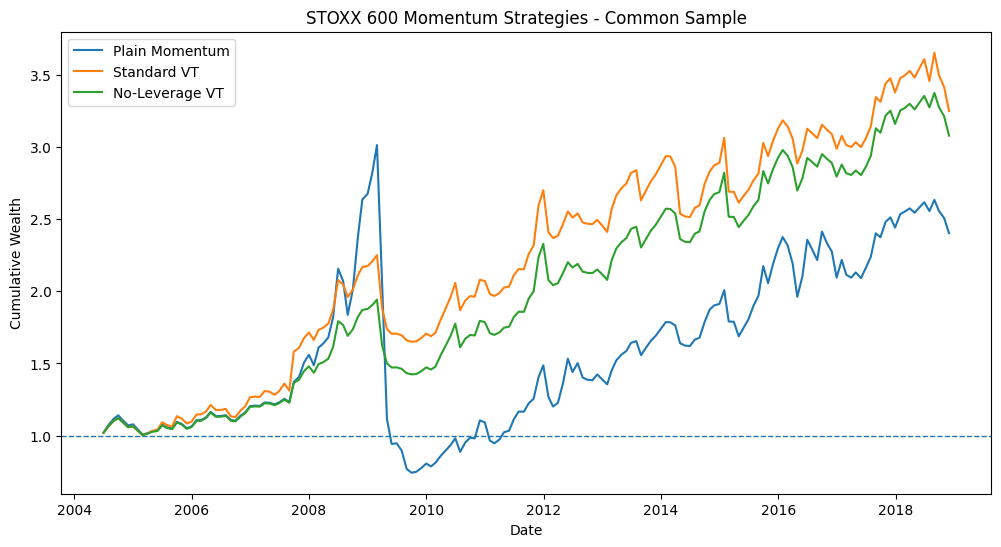

In [ ]:
stoxx_common_wealth = (
    1 + stoxx_common
).cumprod()

plt.figure(figsize=(12, 6))

for column in stoxx_common_wealth.columns:

    plt.plot(
        stoxx_common_wealth.index,
        stoxx_common_wealth[column],
        label=column
    )

plt.axhline(1, linestyle="--", linewidth=1)

plt.title(
    "STOXX 600 Momentum Strategies - Common Sample"
)

plt.ylabel("Cumulative Wealth")
plt.xlabel("Date")
plt.legend()

plt.show()

## Common-sample interpretation

The common sample contains 174 months for both markets, so differences are no
longer driven by unequal calendar coverage.

For the S&P 500, Plain Momentum still has a negative CAGR (-0.75%) and a maximum
drawdown of -78.21%, while Standard VT and No-Leverage VT reduce volatility to
13.90% and 12.55% and improve maximum drawdown to -34.33% and -32.14%.

The STOXX 600 results remain strongly positive over the same dates, with both VT
strategies showing much smaller drawdowns than Plain Momentum.

Therefore, the main risk-management effect of volatility targeting remains visible
when the U.S. and European strategies are evaluated under the same market-time
conditions. The level of momentum profitability, however, remains strongly
market-dependent.


---


# 8. Robustness Checks

The baseline volatility-targeting specification uses:

- a 6-month volatility estimation window;
- a 10% annual volatility target.

To assess whether the main findings depend excessively on these specific
parameter choices, we repeat the analysis using alternative but reasonable
specifications.

We consider:

$$
Volatility\ Window \in \{3,6,12\}\ months
$$

and

$$
Target\ Volatility \in \{8\%,10\%,12\%\}
$$

The purpose is not to select the ex-post best-performing specification.

Instead, the objective is to determine whether the main risk-management
conclusions remain qualitatively stable across alternative parameter choices.

In [ ]:
VOL_WINDOWS = [3, 6, 12]
TARGET_VOLS = [0.08, 0.10, 0.12]


def run_vt_robustness(
    plain_returns,
    vol_windows,
    target_vols,
    max_scaling
):

    strategy_returns = {}

    # Step 1: generate every parameter combination
    for window in vol_windows:

        for target in target_vols:

            vt = apply_volatility_targeting(
                strategy_returns=plain_returns,
                target_vol=target,
                vol_window=window,
                max_scaling=max_scaling
            )

            name = f"W{window}_T{int(target*100)}"

            strategy_returns[name] = vt["VT_Return"]

    # Step 2: combine all strategies
    robustness_returns = pd.DataFrame(
        strategy_returns
    )

    # Step 3: use exactly the same months for every specification
    robustness_returns = robustness_returns.dropna()

    # Step 4: calculate performance statistics
    records = []

    for window in vol_windows:

        for target in target_vols:

            name = f"W{window}_T{int(target*100)}"

            stats = compute_performance_metrics(
                robustness_returns[name]
            )

            record = {
                "Vol_Window": window,
                "Target_Vol": target,
                "Annualized Return": stats["Annualized Return"],
                "CAGR": stats["CAGR"],
                "Annualized Volatility": stats["Annualized Volatility"],
                "Sharpe Ratio": stats["Sharpe Ratio"],
                "Maximum Drawdown": stats["Maximum Drawdown"],
                "Worst Month": stats["Worst Month"]
            }

            records.append(record)

    results = pd.DataFrame(records)

    return results, robustness_returns

In [ ]:
spx_robust_standard, spx_robust_standard_returns = run_vt_robustness(
    plain_returns=spx_plain_momentum["Long_Short"],
    vol_windows=VOL_WINDOWS,
    target_vols=TARGET_VOLS,
    max_scaling=2.0
)

In [ ]:
stoxx_robust_standard, stoxx_robust_standard_returns = run_vt_robustness(
    plain_returns=stoxx_plain_momentum["Long_Short"],
    vol_windows=VOL_WINDOWS,
    target_vols=TARGET_VOLS,
    max_scaling=2.0
)

In [ ]:
spx_robust_nolev, spx_robust_nolev_returns = run_vt_robustness(
    plain_returns=spx_plain_momentum["Long_Short"],
    vol_windows=VOL_WINDOWS,
    target_vols=TARGET_VOLS,
    max_scaling=1.0
)

In [ ]:
stoxx_robust_nolev, stoxx_robust_nolev_returns = run_vt_robustness(
    plain_returns=stoxx_plain_momentum["Long_Short"],
    vol_windows=VOL_WINDOWS,
    target_vols=TARGET_VOLS,
    max_scaling=1.0
)

In [ ]:
spx_robust_plain = (
    spx_plain_momentum["Long_Short"]
    .reindex(spx_robust_standard_returns.index)
    .dropna()
)

stoxx_robust_plain = (
    stoxx_plain_momentum["Long_Short"]
    .reindex(stoxx_robust_standard_returns.index)
    .dropna()
)

print("S&P 500 Plain - Robustness Sample")
display(
    compute_performance_metrics(spx_robust_plain)
)

print("STOXX 600 Plain - Robustness Sample")
display(
    compute_performance_metrics(stoxx_robust_plain)
)

S&P 500 Plain - Robustness Sample


Annualized Return          0.030533
CAGR                      -0.017584
Annualized Volatility      0.290440
Sharpe Ratio               0.105128
Maximum Drawdown          -0.824713
Worst Month               -0.473027
Worst 3 Months            -0.663319
Number of Months         312.000000
dtype: float64

STOXX 600 Plain - Robustness Sample


Annualized Return          0.091601
CAGR                       0.059426
Annualized Volatility      0.242562
Sharpe Ratio               0.377641
Maximum Drawdown          -0.753553
Worst Month               -0.456703
Worst 3 Months            -0.687264
Number of Months         168.000000
dtype: float64

In [ ]:
def format_robustness_table(results):

    table = results.copy()

    percentage_columns = [
        "Target_Vol",
        "Annualized Return",
        "CAGR",
        "Annualized Volatility",
        "Maximum Drawdown",
        "Worst Month"
    ]

    for col in percentage_columns:
        table[col] = (
            table[col] * 100
        ).round(2)

    table["Sharpe Ratio"] = (
        table["Sharpe Ratio"].round(2)
    )

    return table

In [ ]:
print("S&P 500 - Standard VT Robustness")
display(
    format_robustness_table(
        spx_robust_standard
    )
)

print("S&P 500 - No-Leverage VT Robustness")
display(
    format_robustness_table(
        spx_robust_nolev
    )
)

print("STOXX 600 - Standard VT Robustness")
display(
    format_robustness_table(
        stoxx_robust_standard
    )
)

print("STOXX 600 - No-Leverage VT Robustness")
display(
    format_robustness_table(
        stoxx_robust_nolev
    )
)

S&P 500 - Standard VT Robustness


,Vol_Window,Target_Vol,Annualized Return,CAGR,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Worst Month
0,3,8.0,5.06,2.96,19.33,0.26,-62.72,-51.07
1,3,10.0,5.22,1.91,23.06,0.23,-74.00,-63.84
2,3,12.0,5.16,0.02,26.77,0.19,-84.28,-76.60
3,6,8.0,2.81,1.44,15.46,0.18,-53.71,-46.90
4,6,10.0,3.32,1.08,18.93,0.18,-65.31,-58.62
5,6,12.0,3.65,0.17,22.33,0.16,-76.15,-70.35
6,12,8.0,2.87,2.44,9.59,0.30,-27.77,-10.09
7,12,10.0,3.59,2.90,11.99,0.30,-33.71,-12.62
8,12,12.0,4.31,3.31,14.38,0.30,-39.29,-15.14


S&P 500 - No-Leverage VT Robustness


,Vol_Window,Target_Vol,Annualized Return,CAGR,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Worst Month
0,3,8.0,2.69,1.21,16.12,0.17,-56.35,-45.56
1,3,10.0,2.95,1.19,17.73,0.17,-58.58,-45.56
2,3,12.0,3.25,1.27,18.98,0.17,-59.47,-45.56
3,6,8.0,2.06,0.86,14.34,0.14,-52.54,-45.56
4,6,10.0,2.51,1.08,15.92,0.16,-54.36,-45.56
5,6,12.0,2.75,1.13,17.03,0.16,-55.41,-45.56
6,12,8.0,2.89,2.47,9.46,0.31,-27.77,-10.09
7,12,10.0,3.54,2.90,11.55,0.31,-33.71,-12.62
8,12,12.0,3.98,3.11,13.48,0.30,-39.17,-15.14


STOXX 600 - Standard VT Robustness


,Vol_Window,Target_Vol,Annualized Return,CAGR,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Worst Month
0,3,8.0,8.99,7.90,16.20,0.55,-35.19,-26.98
1,3,10.0,10.42,8.83,19.12,0.55,-42.95,-33.73
2,3,12.0,11.90,9.71,21.89,0.54,-50.31,-40.48
3,6,8.0,7.23,6.80,11.34,0.64,-21.72,-13.12
4,6,10.0,9.04,8.35,14.13,0.64,-26.66,-16.40
5,6,12.0,10.70,9.72,16.68,0.64,-31.42,-19.68
6,12,8.0,6.75,6.47,9.77,0.69,-19.51,-8.67
7,12,10.0,8.44,7.99,12.21,0.69,-23.96,-10.84
8,12,12.0,10.08,9.42,14.59,0.69,-28.23,-13.01


STOXX 600 - No-Leverage VT Robustness


,Vol_Window,Target_Vol,Annualized Return,CAGR,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Worst Month
0,3,8.0,7.23,6.45,13.49,0.54,-35.19,-26.98
1,3,10.0,8.42,7.40,15.31,0.55,-41.25,-31.75
2,3,12.0,9.61,8.51,16.31,0.59,-43.03,-31.75
3,6,8.0,6.91,6.54,10.54,0.66,-21.72,-13.12
4,6,10.0,8.44,7.93,12.49,0.68,-26.66,-16.40
5,6,12.0,9.54,8.88,14.02,0.68,-31.42,-19.68
6,12,8.0,6.41,6.14,9.34,0.69,-19.51,-8.67
7,12,10.0,7.72,7.33,11.24,0.69,-23.96,-10.84
8,12,12.0,8.93,8.39,13.00,0.69,-28.23,-13.01


In [ ]:
spx_standard_dd = (
    spx_robust_standard
    .pivot(
        index="Vol_Window",
        columns="Target_Vol",
        values="Maximum Drawdown"
    )
    * 100
)

spx_standard_dd.columns = [
    "8%",
    "10%",
    "12%"
]

print("S&P 500 - Standard VT Maximum Drawdown (%)")
display(spx_standard_dd.round(2))

S&P 500 - Standard VT Maximum Drawdown (%)


,8%,10%,12%
Vol_Window,,,
3,-62.72,-74.00,-84.28
6,-53.71,-65.31,-76.15
12,-27.77,-33.71,-39.29


In [ ]:
spx_standard_sharpe = (
    spx_robust_standard
    .pivot(
        index="Vol_Window",
        columns="Target_Vol",
        values="Sharpe Ratio"
    )
)

spx_standard_sharpe.columns = [
    "8%",
    "10%",
    "12%"
]

print("S&P 500 - Standard VT Sharpe Ratio")
display(
    spx_standard_sharpe.round(2)
)

S&P 500 - Standard VT Sharpe Ratio


,8%,10%,12%
Vol_Window,,,
3,0.26,0.23,0.19
6,0.18,0.18,0.16
12,0.30,0.30,0.30


In [ ]:
stoxx_standard_sharpe = (
    stoxx_robust_standard
    .pivot(
        index="Vol_Window",
        columns="Target_Vol",
        values="Sharpe Ratio"
    )
)

stoxx_standard_sharpe.columns = [
    "8%",
    "10%",
    "12%"
]

print("STOXX 600 - Standard VT Sharpe Ratio")
display(
    stoxx_standard_sharpe.round(2)
)

STOXX 600 - Standard VT Sharpe Ratio


,8%,10%,12%
Vol_Window,,,
3,0.55,0.55,0.54
6,0.64,0.64,0.64
12,0.69,0.69,0.69


## Robustness interpretation

The robustness analysis uses a common sample across all parameter combinations
(312 months for the S&P 500 and 168 months for the STOXX 600). Therefore, the
6-month / 10% figures in this section differ slightly from the baseline figures
reported earlier.

The main conclusion remains visible across a broad set of parameters: volatility
targeting generally reduces risk relative to Plain Momentum in both markets.

The volatility-estimation window matters materially. In this sample, the 12-month
window produces smoother risk estimates, smaller drawdowns and stronger Sharpe
ratios. For example, S&P 500 Standard VT with a 12-month window and 10% target has
a maximum drawdown of -33.71%, compared with -74.00% for the 3-month window.

Short windows are more responsive but can also cause estimated volatility to fall
quickly after a brief calm period. When leverage is allowed, this can create severe
tail risk: S&P 500 Standard VT with a 3-month window and 12% target reaches a
maximum drawdown of -84.28% and a worst month of -76.60%.

The 12-month window should not be interpreted as universally optimal: it reacts
more slowly to new information. The baseline 6-month / 10% specification is kept
unchanged to avoid ex-post parameter selection.


---


# 9. Transaction Costs

The previous analysis evaluates strategy returns before trading costs.

Momentum portfolios require periodic rebalancing as securities move between the
winner and loser portfolios, while volatility targeting can also change the overall
scale of the position.

We therefore use a simple linear transaction-cost model:

$$
R^{net}_t =
R^{gross}_t - c \times TN_t
$$

where \(c\) is the assumed cost per unit of traded notional and

$$
TN_t = \sum_i |w_{i,t}-w_{i,t-1}|.
$$

We refer to this quantity as **traded notional** rather than turnover because turnover
conventions differ across applications.

Transaction costs of 0, 5, 10 and 20 basis points are considered. This is a sensitivity
analysis rather than a complete model of real-world implementation costs.


In [ ]:
def build_momentum_weights(
    signal,
    quantile=0.10,
    min_stocks=30
):

    weights = pd.DataFrame(
        0.0,
        index=signal.index,
        columns=signal.columns
    )

    for date in signal.index:

        signal_t = signal.loc[date].dropna()

        if len(signal_t) < min_stocks:
            continue

        lower_cutoff = signal_t.quantile(quantile)
        upper_cutoff = signal_t.quantile(1 - quantile)

        long_tickers = signal_t[
            signal_t >= upper_cutoff
        ].index

        short_tickers = signal_t[
            signal_t <= lower_cutoff
        ].index

        weights.loc[
            date,
            long_tickers
        ] = 1 / len(long_tickers)

        weights.loc[
            date,
            short_tickers
        ] = -1 / len(short_tickers)

    return weights

In [ ]:
spx_base_weights = build_momentum_weights(
    spx_momentum,
    quantile=MOMENTUM_QUANTILE,
    min_stocks=MIN_STOCKS_FOR_RANKING
)

stoxx_base_weights = build_momentum_weights(
    stoxx_momentum,
    quantile=MOMENTUM_QUANTILE,
    min_stocks=MIN_STOCKS_FOR_RANKING
)

In [ ]:
print(
    "SPX median gross exposure:",
    spx_base_weights.abs().sum(axis=1)
    .replace(0, np.nan)
    .median()
)

print(
    "STOXX median gross exposure:",
    stoxx_base_weights.abs().sum(axis=1)
    .replace(0, np.nan)
    .median()
)

SPX median gross exposure: 2.0
STOXX median gross exposure: 2.0


In [ ]:
spx_cost_weights_plain = (
    spx_base_weights
    .reindex(spx_strategy_comparison.index)
)

stoxx_cost_weights_plain = (
    stoxx_base_weights
    .reindex(stoxx_strategy_comparison.index)
)

In [ ]:
spx_cost_weights_standard = (
    spx_cost_weights_plain.mul(
        spx_vt_standard["Scaling_Factor"]
        .reindex(spx_strategy_comparison.index),
        axis=0
    )
)

stoxx_cost_weights_standard = (
    stoxx_cost_weights_plain.mul(
        stoxx_vt_standard["Scaling_Factor"]
        .reindex(stoxx_strategy_comparison.index),
        axis=0
    )
)

In [ ]:
spx_cost_weights_nolev = (
    spx_cost_weights_plain.mul(
        spx_vt_no_leverage["Scaling_Factor"]
        .reindex(spx_strategy_comparison.index),
        axis=0
    )
)

stoxx_cost_weights_nolev = (
    stoxx_cost_weights_plain.mul(
        stoxx_vt_no_leverage["Scaling_Factor"]
        .reindex(stoxx_strategy_comparison.index),
        axis=0
    )
)

In [ ]:
def compute_traded_notional(weights):

    previous_weights = (
        weights.shift(1).fillna(0)
    )

    traded_notional = (
        weights - previous_weights
    ).abs().sum(axis=1)

    return traded_notional

In [ ]:
spx_turnover = pd.DataFrame({
    "Plain Momentum":
        compute_traded_notional(
            spx_cost_weights_plain
        ),

    "Standard VT":
        compute_traded_notional(
            spx_cost_weights_standard
        ),

    "No-Leverage VT":
        compute_traded_notional(
            spx_cost_weights_nolev
        )
})

stoxx_turnover = pd.DataFrame({
    "Plain Momentum":
        compute_traded_notional(
            stoxx_cost_weights_plain
        ),

    "Standard VT":
        compute_traded_notional(
            stoxx_cost_weights_standard
        ),

    "No-Leverage VT":
        compute_traded_notional(
            stoxx_cost_weights_nolev
        )
})

In [ ]:
print("S&P 500 - Average Monthly Traded Notional")
display(
    spx_turnover.mean().to_frame(
        "Average Monthly Traded Notional"
    )
)

print("STOXX 600 - Average Monthly Traded Notional")
display(
    stoxx_turnover.mean().to_frame(
        "Average Monthly Traded Notional"
    )
)

S&P 500 - Average Monthly Traded Notional


,Average Monthly Traded Notional
Plain Momentum,1.129044
Standard VT,0.971546
No-Leverage VT,0.797818


STOXX 600 - Average Monthly Traded Notional


,Average Monthly Traded Notional
Plain Momentum,1.160234
Standard VT,1.079722
No-Leverage VT,0.889136


In [ ]:
def apply_transaction_costs(
    gross_returns,
    turnover,
    cost_bps
):

    cost_rate = cost_bps / 10000

    net_returns = (
        gross_returns
        - turnover * cost_rate
    )

    return net_returns

In [ ]:
spx_net_10bps = apply_transaction_costs(
    gross_returns=spx_strategy_comparison,
    turnover=spx_turnover,
    cost_bps=10
)

stoxx_net_10bps = apply_transaction_costs(
    gross_returns=stoxx_strategy_comparison,
    turnover=stoxx_turnover,
    cost_bps=10
)

In [ ]:
COST_LEVELS = [0, 5, 10, 20]


def transaction_cost_sensitivity(
    gross_returns,
    turnover,
    cost_levels
):

    records = []

    for cost in cost_levels:

        net_returns = apply_transaction_costs(
            gross_returns,
            turnover,
            cost
        )

        for strategy in gross_returns.columns:

            stats = compute_performance_metrics(
                net_returns[strategy]
            )

            records.append({
                "Cost_bps": cost,
                "Strategy": strategy,
                "Annualized Return":
                    stats["Annualized Return"],
                "CAGR":
                    stats["CAGR"],
                "Annualized Volatility":
                    stats["Annualized Volatility"],
                "Sharpe Ratio":
                    stats["Sharpe Ratio"],
                "Maximum Drawdown":
                    stats["Maximum Drawdown"]
            })

    return pd.DataFrame(records)

In [ ]:
spx_cost_results = transaction_cost_sensitivity(
    gross_returns=spx_strategy_comparison,
    turnover=spx_turnover,
    cost_levels=COST_LEVELS
)

stoxx_cost_results = transaction_cost_sensitivity(
    gross_returns=stoxx_strategy_comparison,
    turnover=stoxx_turnover,
    cost_levels=COST_LEVELS
)

In [ ]:
def format_cost_table(results):

    table = results.copy()

    percentage_columns = [
        "Annualized Return",
        "CAGR",
        "Annualized Volatility",
        "Maximum Drawdown"
    ]

    for col in percentage_columns:
        table[col] = (
            table[col] * 100
        ).round(2)

    table["Sharpe Ratio"] = (
        table["Sharpe Ratio"].round(2)
    )

    return table

In [ ]:
print("S&P 500 - Transaction Cost Sensitivity")
display(
    format_cost_table(
        spx_cost_results
    )
)

print("STOXX 600 - Transaction Cost Sensitivity")
display(
    format_cost_table(
        stoxx_cost_results
    )
)

S&P 500 - Transaction Cost Sensitivity


,Cost_bps,Strategy,Annualized Return,CAGR,Annualized Volatility,Sharpe Ratio,Maximum Drawdown
0,0,Plain Momentum,3.20,-1.53,28.79,0.11,-82.47
1,0,Standard VT,3.47,1.27,18.79,0.18,-65.31
2,0,No-Leverage VT,2.67,1.25,15.81,0.17,-54.36
3,5,Plain Momentum,2.53,-2.20,28.80,0.09,-83.89
4,5,Standard VT,2.89,0.68,18.78,0.15,-65.80
5,5,No-Leverage VT,2.19,0.77,15.81,0.14,-54.93
6,10,Plain Momentum,1.85,-2.86,28.80,0.06,-85.19
7,10,Standard VT,2.31,0.09,18.78,0.12,-67.77
8,10,No-Leverage VT,1.71,0.29,15.82,0.11,-56.75
9,20,Plain Momentum,0.49,-4.18,28.81,0.02,-87.50


STOXX 600 - Transaction Cost Sensitivity


,Cost_bps,Strategy,Annualized Return,CAGR,Annualized Volatility,Sharpe Ratio,Maximum Drawdown
0,0,Plain Momentum,9.34,6.23,23.92,0.39,-75.36
1,0,Standard VT,9.13,8.47,14.00,0.65,-26.66
2,0,No-Leverage VT,8.56,8.06,12.41,0.69,-26.66
3,5,Plain Momentum,8.64,5.50,23.92,0.36,-75.49
4,5,Standard VT,8.49,7.77,14.00,0.61,-26.77
5,5,No-Leverage VT,8.02,7.49,12.41,0.65,-26.77
6,10,Plain Momentum,7.95,4.77,23.93,0.33,-75.62
7,10,Standard VT,7.84,7.08,14.01,0.56,-26.88
8,10,No-Leverage VT,7.49,6.92,12.41,0.60,-26.88
9,20,Plain Momentum,6.56,3.32,23.93,0.27,-75.89


In [ ]:
spx_cost_cagr = (
    spx_cost_results
    .pivot(
        index="Cost_bps",
        columns="Strategy",
        values="CAGR"
    )
    * 100
)

stoxx_cost_cagr = (
    stoxx_cost_results
    .pivot(
        index="Cost_bps",
        columns="Strategy",
        values="CAGR"
    )
    * 100
)

print("S&P 500 - CAGR after Transaction Costs (%)")
display(spx_cost_cagr.round(2))

print("STOXX 600 - CAGR after Transaction Costs (%)")
display(stoxx_cost_cagr.round(2))

S&P 500 - CAGR after Transaction Costs (%)


Strategy,No-Leverage VT,Plain Momentum,Standard VT
Cost_bps,,,
0,1.25,-1.53,1.27
5,0.77,-2.20,0.68
10,0.29,-2.86,0.09
20,-0.67,-4.18,-1.08


STOXX 600 - CAGR after Transaction Costs (%)


Strategy,No-Leverage VT,Plain Momentum,Standard VT
Cost_bps,,,
0,8.06,6.23,8.47
5,7.49,5.50,7.77
10,6.92,4.77,7.08
20,5.80,3.32,5.71


## Transaction-cost interpretation

Trading frictions materially reduce economic performance, while realised volatility
changes little.

Average monthly traded notional is highest for Plain Momentum and lowest for the
No-Leverage specification (1.13, 0.97 and 0.80 for Plain, Standard VT and
No-Leverage VT in the S&P 500; 1.16, 1.08 and 0.89 in the STOXX 600).

The U.S. results are especially sensitive to costs. At 10 bps, CAGR falls to
-2.86% for Plain Momentum, 0.09% for Standard VT and 0.29% for No-Leverage VT.
At 20 bps, both VT specifications have negative CAGR.

The European results are more robust: even at 20 bps, Standard VT and No-Leverage
VT retain CAGR of 5.71% and 5.80%, respectively.

The cost model remains deliberately simplified. It does not explicitly include
stock-borrowing fees, bid-ask spreads, market impact, taxes or time-varying
liquidity, so these results should be interpreted as a sensitivity analysis rather
than a complete implementation-cost estimate.


---


# Final Benchmark Check

As a final reference before drawing conclusions, the momentum strategies are compared
with the equity index representing each investment universe.

The benchmark is not directly equivalent to the momentum portfolios: the index is
a long-only equity investment, whereas the momentum strategies are long-short.

Therefore, the comparison provides economic context rather than a like-for-like
strategy ranking. Benchmark performance is evaluated over the same dates used for
the corresponding momentum strategy comparison.


## Monthly Benchmark Data

The `AC` sheets contain index series at different frequencies.

Since the momentum strategies are constructed and evaluated at monthly frequency,
the benchmark must also be measured monthly.

The monthly benchmark series are therefore extracted explicitly from the
corresponding monthly date and index columns.

In [ ]:
# Read AC sheets
spx_ac = pd.read_excel(
    SPX_FILE,
    sheet_name="AC",
    index_col=0
)

stoxx_ac = pd.read_excel(
    STOXX_FILE,
    sheet_name="AC",
    index_col=0
)


# -------------------------
# S&P 500 monthly benchmark
# -------------------------

spx_benchmark_data = pd.DataFrame({
    "Date": pd.to_datetime(
        spx_ac["Dates.1"],
        errors="coerce"
    ),
    "Index_Level": pd.to_numeric(
        spx_ac["SPX Index.1"],
        errors="coerce"
    )
})

spx_benchmark_data = (
    spx_benchmark_data
    .dropna(subset=["Date", "Index_Level"])
    .sort_values("Date")
    .set_index("Date")
)


# -------------------------
# STOXX 600 monthly benchmark
# -------------------------

stoxx_benchmark_data = pd.DataFrame({
    "Date": pd.to_datetime(
        stoxx_ac["Dates.1"],
        errors="coerce"
    ),
    "Index_Level": pd.to_numeric(
        stoxx_ac["SXXP Index"],
        errors="coerce"
    )
})

stoxx_benchmark_data = (
    stoxx_benchmark_data
    .dropna(subset=["Date", "Index_Level"])
    .sort_values("Date")
    .set_index("Date")
)


print("S&P 500 monthly benchmark")
display(spx_benchmark_data.head())

print("STOXX 600 monthly benchmark")
display(stoxx_benchmark_data.head())

S&P 500 monthly benchmark


,Index_Level
Date,
1990-12-31,330.22
1991-01-31,343.93
1991-02-28,367.07
1991-03-29,375.22
1991-04-30,375.35


STOXX 600 monthly benchmark


,Index_Level
Date,
2002-12-31,203.25
2003-01-31,189.00
2003-02-28,181.75
2003-03-31,176.41
2003-04-30,194.88


## Benchmark Monthly Returns

Benchmark index levels are converted into monthly simple returns:

$$
R_t = \frac{P_t}{P_{t-1}} - 1
$$

This makes the benchmark returns directly comparable with the monthly returns
used throughout the momentum analysis.

In [ ]:
spx_benchmark_returns = (
    spx_benchmark_data["Index_Level"]
    .pct_change(fill_method=None)
    .dropna()
)

stoxx_benchmark_returns = (
    stoxx_benchmark_data["Index_Level"]
    .pct_change(fill_method=None)
    .dropna()
)

print("S&P benchmark returns")
display(spx_benchmark_returns.head())

print("STOXX benchmark returns")
display(stoxx_benchmark_returns.head())

S&P benchmark returns


Date
1991-01-31    0.041518
1991-02-28    0.067281
1991-03-29    0.022203
1991-04-30    0.000346
1991-05-31    0.038577
Name: Index_Level, dtype: float64

STOXX benchmark returns


Date
2003-01-31   -0.070111
2003-02-28   -0.038360
2003-03-31   -0.029381
2003-04-30    0.104699
2003-05-30    0.008518
Name: Index_Level, dtype: float64

## Benchmark Alignment

The benchmark and momentum datasets may identify the same month using slightly
different calendar dates, such as the last trading day versus the calendar
month-end.

Therefore, benchmark returns are aligned to strategy returns by year and month
rather than by requiring an exact daily date match.

In [ ]:
def align_monthly_benchmark(
    benchmark_returns,
    strategy_index
):

    benchmark = benchmark_returns.copy()

    # Convert benchmark dates to monthly periods
    benchmark.index = benchmark.index.to_period("M")

    # Convert strategy dates to monthly periods
    strategy_periods = strategy_index.to_period("M")

    # Align benchmark to the months used by the strategy
    aligned = benchmark.reindex(strategy_periods)

    # Restore the original strategy dates
    aligned.index = strategy_index

    return aligned

In [ ]:
spx_benchmark_comparison = align_monthly_benchmark(
    benchmark_returns=spx_benchmark_returns,
    strategy_index=spx_strategy_comparison.index
)

stoxx_benchmark_comparison = align_monthly_benchmark(
    benchmark_returns=stoxx_benchmark_returns,
    strategy_index=stoxx_strategy_comparison.index
)


print(
    "S&P benchmark valid months:",
    spx_benchmark_comparison.notna().sum(),
    "out of",
    len(spx_strategy_comparison)
)

print(
    "STOXX benchmark valid months:",
    stoxx_benchmark_comparison.notna().sum(),
    "out of",
    len(stoxx_strategy_comparison)
)

S&P benchmark valid months: 318 out of 318
STOXX benchmark valid months: 174 out of 174


## Benchmark Performance

The same performance and risk measures used for the momentum strategies are now
calculated for the corresponding equity-market benchmark.

The comparison provides economic context, although it should not be interpreted
as a perfect like-for-like comparison because the benchmark is long-only whereas
the momentum portfolios are long-short.

In [ ]:
spx_benchmark_stats = compute_performance_metrics(
    spx_benchmark_comparison
)

stoxx_benchmark_stats = compute_performance_metrics(
    stoxx_benchmark_comparison
)

print("S&P 500 Index")
display(spx_benchmark_stats)

print("STOXX 600 Index")
display(stoxx_benchmark_stats)

S&P 500 Index


Annualized Return          0.081567
CAGR                       0.074085
Annualized Volatility      0.139771
Sharpe Ratio               0.583574
Maximum Drawdown          -0.525559
Worst Month               -0.169425
Worst 3 Months            -0.301357
Number of Months         318.000000
dtype: float64

STOXX 600 Index


Annualized Return          0.037742
CAGR                       0.028649
Annualized Volatility      0.136932
Sharpe Ratio               0.275627
Maximum Drawdown          -0.564148
Worst Month               -0.132708
Worst 3 Months            -0.284301
Number of Months         174.000000
dtype: float64

In [ ]:
spx_final_comparison = spx_comparison_stats.copy()

spx_final_comparison.loc[
    "S&P 500 Index"
] = spx_benchmark_stats


stoxx_final_comparison = stoxx_comparison_stats.copy()

stoxx_final_comparison.loc[
    "STOXX 600 Index"
] = stoxx_benchmark_stats

In [ ]:
final_percentage_columns = [
    "Annualized Return",
    "CAGR",
    "Annualized Volatility",
    "Maximum Drawdown",
    "Worst Month",
    "Worst 3 Months"
]

spx_final_display = spx_final_comparison.copy()
stoxx_final_display = stoxx_final_comparison.copy()

for col in final_percentage_columns:

    spx_final_display[col] = (
        spx_final_display[col] * 100
    ).round(2)

    stoxx_final_display[col] = (
        stoxx_final_display[col] * 100
    ).round(2)

spx_final_display["Sharpe Ratio"] = (
    spx_final_display["Sharpe Ratio"].round(2)
)

stoxx_final_display["Sharpe Ratio"] = (
    stoxx_final_display["Sharpe Ratio"].round(2)
)

print("S&P 500 - Final Strategy and Benchmark Comparison")
display(spx_final_display)

print("STOXX 600 - Final Strategy and Benchmark Comparison")
display(stoxx_final_display)

S&P 500 - Final Strategy and Benchmark Comparison


,Annualized Return,CAGR,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Worst Month,Worst 3 Months,Number of Months
Plain Momentum,3.20,-1.53,28.79,0.11,-82.47,-47.30,-66.33,318.0
Standard VT,3.47,1.27,18.79,0.18,-65.31,-58.62,-58.44,318.0
No-Leverage VT,2.67,1.25,15.81,0.17,-54.36,-45.56,-45.32,318.0
S&P 500 Index,8.16,7.41,13.98,0.58,-52.56,-16.94,-30.14,318.0


STOXX 600 - Final Strategy and Benchmark Comparison


,Annualized Return,CAGR,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Worst Month,Worst 3 Months,Number of Months
Plain Momentum,9.34,6.23,23.92,0.39,-75.36,-45.67,-68.73,174.0
Standard VT,9.13,8.47,14.00,0.65,-26.66,-16.40,-24.21,174.0
No-Leverage VT,8.56,8.06,12.41,0.69,-26.66,-16.40,-24.21,174.0
STOXX 600 Index,3.77,2.86,13.69,0.28,-56.41,-13.27,-28.43,174.0


## Benchmark Interpretation

The benchmark comparison reveals substantial differences across markets.

In the S&P 500 sample, the equity index exhibits considerably stronger performance
than the momentum strategies, with higher CAGR and Sharpe ratio and lower realised
volatility. Volatility targeting substantially improves the risk profile of plain
momentum, but it does not make the U.S. momentum strategy superior to the long-only
equity benchmark over this sample.

The European evidence is different. Both volatility-targeted momentum strategies
achieve higher compound growth and substantially better risk-adjusted performance
than the STOXX 600 benchmark, while also experiencing much smaller maximum drawdowns.

These results indicate that the risk-management effect of volatility targeting is
visible in both markets, but the economic attractiveness of momentum relative to
the underlying equity index is strongly market- and sample-dependent.

The benchmark comparison should nevertheless be interpreted with caution because
the equity indices are long-only investments, whereas the momentum portfolios are
long-short strategies with a fundamentally different exposure structure.

---


# 10. Conclusions and Limitations

## Research Question

This project investigates whether volatility targeting can reduce the crash risk
of cross-sectional momentum and whether allowing leverage during low-volatility
periods can create additional tail risk when volatility rises unexpectedly.

The analysis compares:

- Plain 12–1 cross-sectional momentum;
- Standard volatility targeting with a maximum scaling factor of 2;
- No-additional-leverage volatility targeting with a maximum scaling factor of 1.

The strategies are tested on both the S&P 500 and STOXX 600 universes.

## Main Findings

1. **Plain Momentum has severe crash risk.** Maximum drawdown reaches -82.47% in
   the S&P 500 and -75.36% in the STOXX 600.

2. **Volatility targeting primarily improves risk management.** Both VT variants
   reduce volatility and drawdowns substantially, and lower volatility improves
   compound wealth growth.

3. **Momentum crashes are mainly driven by loser rebounds.** The short leg is the
   dominant negative contribution in almost all of the ten worst crash months.

4. **Leverage creates conditional tail risk.** Standard VT can amplify a sudden
   crash when low past volatility leads to scaling above 1 immediately before the
   shock. No-Leverage VT removes this specific amplification channel.

5. **Results are robust but not universal.** The risk-management effect appears in
   both markets and across alternative parameter choices, while transaction costs
   and benchmark comparisons show that economic attractiveness is strongly
   market- and sample-dependent.


## Limitations

Several limitations should be considered when interpreting the results.

1. The analysis is based on historical monthly data ending in 2018, and therefore
   the results may not represent future market conditions.

2. Only two equity universes are considered: the S&P 500 and STOXX 600.
   Cross-market evidence improves robustness, but it does not establish universal validity.

3. The volatility forecast is backward-looking. Volatility targeting reacts to
   previously observed risk and cannot predict sudden regime changes.

4. Transaction costs are represented using a simplified linear model.
   Stock-borrowing fees, bid-ask spreads, market impact, taxes and time-varying
   liquidity are not explicitly modelled.

5. The transaction-cost turnover measure is an approximation based on changes in
   target portfolio weights and does not fully model portfolio-weight drift between
   rebalancing dates.

6. Although the datasets are designed to mitigate survivorship bias and historical
   membership is explicitly considered, security-level data may still contain issues
   related to stale prices, corporate actions and duplicate share classes.

7. Parameter robustness is evaluated within the historical sample rather than through
   a completely independent out-of-sample experiment.

8. The analysis focuses primarily on economic and risk-management performance.
   Statistical significance and factor-adjusted alpha are not the main focus of this project.

9. The benchmark comparison is not fully like-for-like because the equity indices are
   long-only investments, whereas the momentum portfolios are long-short strategies.


## Final Conclusion

The evidence suggests that volatility targeting can substantially improve the
risk profile of cross-sectional momentum.

Across both the S&P 500 and STOXX 600, volatility scaling generally reduces
realised volatility, drawdowns and the negative effect of compounding losses.
The crash analysis shows that the most severe momentum losses are predominantly
associated with sharp rebounds of past losers.

Volatility targeting provides strong protection when risk is already elevated
before the crash because portfolio exposure has been reduced. However, the method
is backward-looking. When a sudden momentum crash follows a low-volatility period,
Standard VT may enter the episode with leveraged exposure and amplify the loss.
The No-Leverage specification removes this specific amplification mechanism, at
the cost of giving up additional exposure during favourable low-volatility periods.

The robustness analysis shows that these conclusions are not restricted to the
baseline 6-month / 10% specification. In this sample, 12-month volatility estimates
are more stable, while short windows combined with leverage can generate substantial
tail risk. The baseline specification is nevertheless retained to avoid ex-post
parameter selection.

Transaction costs materially affect practical implementation. The U.S. results
are relatively fragile to trading costs, whereas the European results remain more
robust under the cost assumptions considered.

The benchmark comparison further shows that economic attractiveness is not uniform
across markets. In the U.S. sample, the long-only S&P 500 index has much stronger
CAGR and Sharpe performance than the momentum strategies. In the European sample,
the volatility-targeted momentum strategies show stronger compound growth and
risk-adjusted performance than the STOXX 600 index. Because the benchmarks are
long-only and momentum is long-short, this comparison is contextual rather than
strictly like-for-like.

Overall, the main benefit of volatility targeting in this study comes from
controlling risk and improving the path of compound wealth rather than from
systematically increasing average returns.


---
